# Du bao khach hang roi mang Telco: Master Notebook

**Mon hoc:** Hoc thong ke (Statistical Learning) · **Dataset:** Telco Customer Churn (7.043 khach hang, 21 cot) · **Nhom:** DS66B - Nhom 11

## Muc luc

| Section | Noi dung | Task trong tracker |
|---|---|---|
| 1 | Bo cong cu dung chung (hang so, ham tien ich, split) | Dung chung toan nhom |
| 2 | EDA: kiem dinh thong ke, lam sach du lieu | Task 1.2, 1.3 |
| 3 | Feature Engineering, Preprocessing Pipeline va xu ly mat can bang | Task 1.4, 1.5 |
| 4 | Candidate Modeling, so sanh, chon champion, dieu chinh nguong | Task 1.6, 2.1, 2.2, 2.3 |
| 5 | Ma tran chi phi kinh te (4B), Odds Ratio, SHAP va chien luoc giu chan (5) | Task 2.4 |

Chay bang **Kernel -> Restart & Run All**.

## 1. Bộ công cụ dùng chung (Shared Toolkit)

Section 1 được chia thành 5 nhóm: import thư viện và thiết lập đường dẫn, hàm làm sạch dữ liệu, chia tập dữ liệu, pipeline tiền xử lý và các hàm phụ trợ đánh giá metric. Hai nhóm cuối được xây dựng sẵn để các thành viên trong nhóm có thể sử dụng lại đồng bộ. Toàn bộ phần này không phụ thuộc vào dữ liệu đã load và chỉ định nghĩa tên biến, hàm dùng chung.

**Quy ước lưu trữ tệp:** Notebook tìm kiếm tệp CSV thô tại `data/raw/telco_customer_churn.csv`, hoặc ngay cạnh notebook (`telco_customer_churn.csv` hoặc tên gốc từ Kaggle `WA_Fn-UseC_-Telco-Customer-Churn.csv`). Các kết quả đầu ra được tự động ghi vào `data/processed/`, `artifacts/` và `reports/figures/` (tự động tạo thư mục nếu chưa có).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "telco_customer_churn.csv",
    PROJECT_ROOT / "telco_customer_churn.csv",
    PROJECT_ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
RAW_DATA_PATH = next((path for path in RAW_DATA_CANDIDATES if path.exists()), None)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, ARTIFACTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_CV_FOLDS = 5
SIGNIFICANCE_LEVEL = 0.05

ID_COLUMN = "customerID"
TARGET_COLUMN = "Churn"
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
INTERNET_DEPENDENT_FEATURES = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
def load_raw_customers(path=RAW_DATA_PATH):
    """Read the original CSV without changing anything."""
    if path is None:
        searched = "\n".join(str(candidate) for candidate in RAW_DATA_CANDIDATES)
        raise FileNotFoundError(f"Raw CSV not found. Put it in one of:\n{searched}")
    return pd.read_csv(path)


def clean_customers(customers_raw):
    """Return a cleaned copy indexed by customerID.

    Rules fixed by business logic (not estimated from data), so applying them
    before the split cannot leak test information: strip whitespace, convert
    TotalCharges to float, set the blank TotalCharges of never-billed customers
    (tenure == 0) to 0, and merge "No internet service" / "No phone service" into "No".
    """
    if customers_raw[ID_COLUMN].duplicated().any():
        raise ValueError("customerID must be unique.")

    customers = customers_raw.copy()
    for column in customers.select_dtypes(exclude="number").columns:
        customers[column] = customers[column].str.strip()

    total_charges_is_blank = customers["TotalCharges"].eq("")
    customer_never_billed = customers["tenure"].eq(0)
    if not total_charges_is_blank.equals(customer_never_billed):
        raise ValueError("Blank TotalCharges no longer matches tenure == 0.")

    total_charges = pd.to_numeric(
        customers["TotalCharges"].where(~total_charges_is_blank), errors="raise"
    )
    customers["TotalCharges"] = total_charges.fillna(0.0).astype("float64")

    merge_redundant_service_labels(customers)
    return customers.set_index(ID_COLUMN)


def merge_redundant_service_labels(customers):
    """Replace "No internet service" / "No phone service" by "No", in place."""
    redundant_label_rules = [
        (INTERNET_DEPENDENT_FEATURES, "No internet service", customers["InternetService"].eq("No")),
        (["MultipleLines"], "No phone service", customers["PhoneService"].eq("No")),
    ]
    for columns, redundant_label, implied_by_other_column in redundant_label_rules:
        for column in columns:
            if not customers[column].eq(redundant_label).equals(implied_by_other_column):
                raise ValueError(f"'{redundant_label}' in {column} is not fully implied by another column.")
            customers[column] = customers[column].replace(redundant_label, "No")

In [3]:
def split_train_test(customers):
    """Stratified 80/20 split shared by the whole team.

    Returns X_train, X_test, y_train, y_test where y is 1 for churn, 0 otherwise.
    """
    features = customers[ALL_FEATURES]
    target = customers[TARGET_COLUMN].map({"No": 0, "Yes": 1}).astype("int64")
    return train_test_split(
        features, target,
        test_size=TEST_SIZE, stratify=target, random_state=RANDOM_STATE,
    )

In [4]:
def build_preprocessor():
    """Unfitted ColumnTransformer: scale numeric, one-hot encode categorical.

    Always place it inside a Pipeline so fit() only sees training data,
    including inside every cross-validation fold.
    """
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return preprocessor.set_output(transform="pandas")


def build_model_pipeline(estimator):
    """Preprocessing + estimator as one object, ready for fit/predict/GridSearchCV."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])


def get_feature_names(fitted_pipeline):
    """Column names produced by the fitted preprocessing step."""
    return list(fitted_pipeline.named_steps["preprocess"].get_feature_names_out())

In [5]:
def compute_basic_metrics(y_true, y_pred):
    """Accuracy and churn-class (label 1) precision, recall, F1."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def make_logistic_regression(penalty, C=1.0):
    """L1 or L2 logistic regression that runs without warnings on scikit-learn 1.2+.

    scikit-learn 1.8 replaced `penalty` with `l1_ratio` (1.0 means L1, 0.0 means L2).
    liblinear supports both penalties on this small dataset.
    """
    if penalty not in ("l1", "l2"):
        raise ValueError("penalty must be 'l1' or 'l2'.")
    if SKLEARN_VERSION >= (1, 8):
        penalty_settings = {"l1_ratio": 1.0 if penalty == "l1" else 0.0}
    else:
        penalty_settings = {"penalty": penalty}
    return LogisticRegression(
        C=C, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **penalty_settings
    )

## 2. Tải và kiểm tra tính toàn vẹn của dữ liệu thô (Audit Raw Data)

Dữ liệu thô được tải nguyên bản trước tiên. Bước kiểm tra nhằm phát hiện các vấn đề mà hàm `isna()` đơn thuần không thấy được: chuỗi ký tự khoảng trắng (blank), bản ghi trùng lặp (duplicate), nhãn không nhất quán và giá trị bất hợp lý. Mỗi phát hiện là căn cứ cho một quy tắc làm sạch dữ liệu tương ứng.


In [6]:
customers_raw = load_raw_customers()
print(f"Rows: {customers_raw.shape[0]:,} | Columns: {customers_raw.shape[1]}")
customers_raw.head()

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [7]:
customers_raw.dtypes.to_frame("raw_dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
raw_dtype,object,object,int64,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,float64,object,object


`TotalCharges` được lưu dưới dạng chuỗi văn bản (object) dù mang giá trị tiền tệ, nghĩa là cột này chứa ít nhất một giá trị không phải số. Cell tiếp theo đếm số giá trị bị thiếu theo 2 cách: `NaN` thực tế và chuỗi ký tự khoảng trắng.


In [8]:
text_columns = customers_raw.select_dtypes(exclude="number")
missing_overview = pd.DataFrame({
    "nan_count": customers_raw.isna().sum(),
    "blank_text_count": text_columns.apply(lambda column: column.str.strip().eq("").sum()),
}).fillna(0).astype(int)
missing_overview[missing_overview.sum(axis=1) > 0]

,nan_count,blank_text_count
TotalCharges,0,11


`isna()` reports no missing values, yet 11 `TotalCharges` cells are blank text. Here are those customers.

In [9]:
blank_total_charges = customers_raw[customers_raw["TotalCharges"].str.strip().eq("")]
display(blank_total_charges[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

print("Every blank row has tenure == 0:", blank_total_charges["tenure"].eq(0).all())
print("Rows with tenure == 0 in the whole dataset:", customers_raw["tenure"].eq(0).sum())
print("Churn labels among blank rows:", blank_total_charges["Churn"].value_counts().to_dict())

,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.5500,,Two year,No
753,0,20.2500,,Two year,No
936,0,80.8500,,Two year,No
1082,0,25.7500,,Two year,No
1340,0,56.0500,,Two year,No
3331,0,19.8500,,Two year,No
3826,0,25.3500,,Two year,No
4380,0,20.0000,,Two year,No
5218,0,19.7000,,One year,No
6670,0,73.3500,,Two year,No


Every blank row has tenure == 0: True
Rows with tenure == 0 in the whole dataset: 11
Churn labels among blank rows: {'No': 11}


**Kết quả kiểm tra:** 11 ô bị trống (blank) tương ứng chính xác với 11 khách hàng có `tenure == 0`. Đây là những khách hàng mới đăng ký và chưa nhận hóa đơn cước đầu tiên, do đó tổng tiền cước thực tế bằng 0. Việc gán `TotalCharges = 0` là một sự điều chỉnh theo bản chất nghiệp vụ chứ không phải ước lượng thống kê (imputation), và không cần dùng thông tin phân phối từ dữ liệu. Vì vậy, việc này hoàn toàn an toàn khi thực hiện trước khi chia tập Train/Test.


In [10]:
duplicated_ids = customers_raw["customerID"].duplicated().sum()
rows_identical_except_id = customers_raw.drop(columns="customerID").duplicated().sum()
print("Duplicated customerID:", duplicated_ids)
print("Rows identical in every column except customerID:", rows_identical_except_id)

Duplicated customerID: 0
Rows identical in every column except customerID: 22


Customer IDs are unique, so no customer appears twice. A small number of different customers share an identical profile, which is expected when 16 of 19 features are categorical. These rows are kept.

In [11]:
for column in CATEGORICAL_FEATURES:
    print(f"{column:<18}", sorted(customers_raw[column].unique()))
customers_raw[["tenure", "MonthlyCharges"]].describe()

gender             ['Female', 'Male']
SeniorCitizen      [np.int64(0), np.int64(1)]
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


,tenure,MonthlyCharges
count,7043.0000,7043.0000
mean,32.3711,64.7617
std,24.5595,30.0900
min,0.0000,18.2500
25%,9.0000,35.5000
50%,29.0000,70.3500
75%,55.0000,89.8500
max,72.0000,118.7500


Các nhãn được chuẩn hóa nhất quán (không bị sai lệch chữ hoa/thường hay khoảng trắng), `SeniorCitizen` chỉ gồm 0 và 1, `tenure` nằm trong khoảng 0 đến 72 tháng và `MonthlyCharges` luôn dương. Bước kiểm tra cấu trúc cuối cùng xác nhận nhãn 'No internet service' và 'No phone service' chỉ xuất hiện khi `InternetService == 'No'` hoặc `PhoneService == 'No'`. Chúng không mang thêm thông tin độc lập nào ngoài 2 biến dịch vụ chính.


In [12]:
internet_dependent_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
has_no_internet = customers_raw["InternetService"].eq("No")
has_no_phone = customers_raw["PhoneService"].eq("No")

consistency_checks = {
    f"{column}: 'No internet service' iff InternetService == 'No'":
        customers_raw[column].eq("No internet service").equals(has_no_internet)
    for column in internet_dependent_columns
}
consistency_checks["MultipleLines: 'No phone service' iff PhoneService == 'No'"] = (
    customers_raw["MultipleLines"].eq("No phone service").equals(has_no_phone)
)
consistency_checks["SeniorCitizen only contains 0 and 1"] = set(customers_raw["SeniorCitizen"]) == {0, 1}
consistency_checks["tenure within 0..72"] = customers_raw["tenure"].between(0, 72).all()
consistency_checks["MonthlyCharges > 0"] = customers_raw["MonthlyCharges"].gt(0).all()

pd.Series(consistency_checks, name="passed").to_frame()

,passed
OnlineSecurity: 'No internet service' iff InternetService == 'No',True
OnlineBackup: 'No internet service' iff InternetService == 'No',True
DeviceProtection: 'No internet service' iff InternetService == 'No',True
TechSupport: 'No internet service' iff InternetService == 'No',True
StreamingTV: 'No internet service' iff InternetService == 'No',True
StreamingMovies: 'No internet service' iff InternetService == 'No',True
MultipleLines: 'No phone service' iff PhoneService == 'No',True
SeniorCitizen only contains 0 and 1,True
tenure within 0..72,True
MonthlyCharges > 0,True


In [13]:
assert all(consistency_checks.values())

total_charges_numeric = pd.to_numeric(customers_raw["TotalCharges"], errors="coerce")
billed_customers = customers_raw["tenure"].gt(0)
expected_total = customers_raw["tenure"] * customers_raw["MonthlyCharges"]
relative_gap = ((total_charges_numeric - expected_total).abs() / expected_total)[billed_customers]
relative_gap.describe(percentiles=[0.5, 0.95]).to_frame("|TotalCharges - tenure x MonthlyCharges| / expected")

,|TotalCharges - tenure x MonthlyCharges| / expected
count,7032.0000
mean,0.0320
std,0.0399
min,0.0000
50%,0.0200
95%,0.1032
max,0.5735


`TotalCharges` xấp xỉ bằng `tenure × MonthlyCharges` đối với hầu hết khách hàng (độ lệch trung vị khoảng 2%), độ lệch lớn hơn xuất hiện ở nhóm khách hàng có thay đổi gói cước theo thời gian. Điều này cho thấy `TotalCharges` về bản chất là tích số của hai biến số còn lại, dẫn đến hiện tượng cộng tuyến tự nhiên giữa chúng (cần lưu ý khi diễn giải hệ số hồi quy).


## 3. Làm sạch dữ liệu (Nhiệm vụ 1.2 trong Tracker)

Hàm `clean_customers()` (Section 1) thực hiện 4 bước:

1. Loại bỏ khoảng trắng thừa ở các cột dạng chuỗi ký tự.
2. Chuyển đổi `TotalCharges` sang kiểu số thực `float` và điền 0 cho 11 ô trống (`tenure == 0`).
3. Gộp nhãn 'No internet service' và 'No phone service' thành 'No' trong 7 cột dịch vụ phụ thuộc. Kết quả kiểm tra ở bước trước đã chứng minh các nhãn này chỉ lặp lại thông tin của `InternetService == 'No'` và `PhoneService == 'No'`. Nếu giữ nguyên, 6 cột phụ thuộc internet sẽ trở thành các cột dummy trùng lặp hoàn toàn, gây khó khăn cho hồi quy tuyến tính.
4. Sử dụng `customerID` làm chỉ mục hàng (index), cho phép truy xuất nguồn gốc từng khách hàng (cần thiết cho biểu đồ SHAP waterfall ở Section 5).

Hàm sẽ báo lỗi ngay lập tức nếu các ô trống không khớp với `tenure == 0` hoặc nhãn dư thừa không được suy ra hoàn toàn từ cột gốc.


In [14]:
customers = clean_customers(customers_raw)

assert len(customers) == len(customers_raw)
assert customers["TotalCharges"].dtype == "float64"
assert customers.isna().sum().sum() == 0
assert customers.loc[customers["tenure"].eq(0), "TotalCharges"].eq(0).all()
assert all(customers[column].nunique() == 2 for column in INTERNET_DEPENDENT_FEATURES + ["MultipleLines"])

cleaning_summary = pd.DataFrame({
    "before": {
        "TotalCharges dtype": str(customers_raw["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers_raw["TotalCharges"].str.strip().eq("").sum()),
        "rows": len(customers_raw),
        "labels in OnlineSecurity": customers_raw["OnlineSecurity"].nunique(),
    },
    "after": {
        "TotalCharges dtype": str(customers["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers["TotalCharges"].isna().sum()),
        "rows": len(customers),
        "labels in OnlineSecurity": customers["OnlineSecurity"].nunique(),
    },
})
cleaning_summary

,before,after
TotalCharges dtype,object,float64
blank TotalCharges cells,11,0
rows,7043,7043
labels in OnlineSecurity,3,2


## 4. Chia tập Train/Test phân tầng (Stratified Split)

Biến mục tiêu bị mất cân bằng (khoảng 26,5% khách hàng rời mạng - churn), do đó chia ngẫu nhiên thông thường có thể làm lệch tỷ lệ này giữa hai tập. Hàm `split_train_test()` sử dụng `test_size=0.20`, `stratify=y` và `random_state=42` (các hằng số cố định từ Section 1) để đảm bảo phân tầng hoàn hảo.

**Kỷ luật chống rò rỉ dữ liệu:** Kể từ thời điểm này, tập Test được khóa lại. Toàn bộ quá trình khám phá EDA và huấn luyện dưới đây chỉ được tiếp cận `X_train` và `y_train`.


In [15]:
X_train, X_test, y_train, y_test = split_train_test(customers)

split_overview = pd.DataFrame(
    {"rows": [len(y_train), len(y_test)], "churn_rate": [y_train.mean(), y_test.mean()]},
    index=["train", "test"],
)
assert set(X_train.index).isdisjoint(X_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.001
split_overview

,rows,churn_rate
train,5634,0.2654
test,1409,0.2654


In [16]:
X_train.join(y_train).to_csv(PROCESSED_DIR / "train.csv")
X_test.join(y_test).to_csv(PROCESSED_DIR / "test.csv")

## 5. Descriptive statistics and inferential tests (tracker Task 1.3, train set only)

Nothing in this section touches `X_test`. `train_df` is the training features joined with the target `Churn` (1 = churned).

In [17]:
train_df = X_train.join(y_train)
print(f"train_df: {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")

train_df: 5,634 rows, 20 columns


### 5.1 Mean, median, skewness, kurtosis and IQR

In [18]:
first_quartile = train_df[NUMERIC_FEATURES].quantile(0.25)
third_quartile = train_df[NUMERIC_FEATURES].quantile(0.75)
interquartile_range = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * interquartile_range
upper_fence = third_quartile + 1.5 * interquartile_range

outlier_count = pd.Series({
    column: ((train_df[column] < lower_fence[column]) | (train_df[column] > upper_fence[column])).sum()
    for column in NUMERIC_FEATURES
})

descriptive_stats = pd.DataFrame({
    "mean": train_df[NUMERIC_FEATURES].mean(),
    "median": train_df[NUMERIC_FEATURES].median(),
    "std": train_df[NUMERIC_FEATURES].std(),
    "skewness": train_df[NUMERIC_FEATURES].skew(),
    "excess_kurtosis": train_df[NUMERIC_FEATURES].kurt(),
    "iqr": interquartile_range,
    "outliers": outlier_count,
})
descriptive_stats.to_csv(ARTIFACTS_DIR / "eda_descriptive_stats.csv")
descriptive_stats

,mean,median,std,skewness,excess_kurtosis,iqr,outliers
tenure,32.4851,29.0000,24.5687,0.2374,-1.3873,46.0000,0
MonthlyCharges,64.9300,70.5000,30.1381,-0.2244,-1.2604,54.3375,0
TotalCharges,2299.3347,1394.9250,2279.2043,0.9490,-0.2646,3432.8500,0


**Reading the table.** `TotalCharges` is right-skewed (skewness 0.95, mean 2,299 above median 1,395) because many customers are recent and have been billed for only a few months. `tenure` and `MonthlyCharges` are close to symmetric (skewness between -0.25 and 0.25) and flatter than a normal curve (excess kurtosis about -1.4 and -1.3). No feature has a single point outside the 1.5 × IQR fences, so no outlier removal is needed, and `StandardScaler` in the pipeline is enough to put the three features on one scale.

### 5.2 Boxplots (IQR rule)

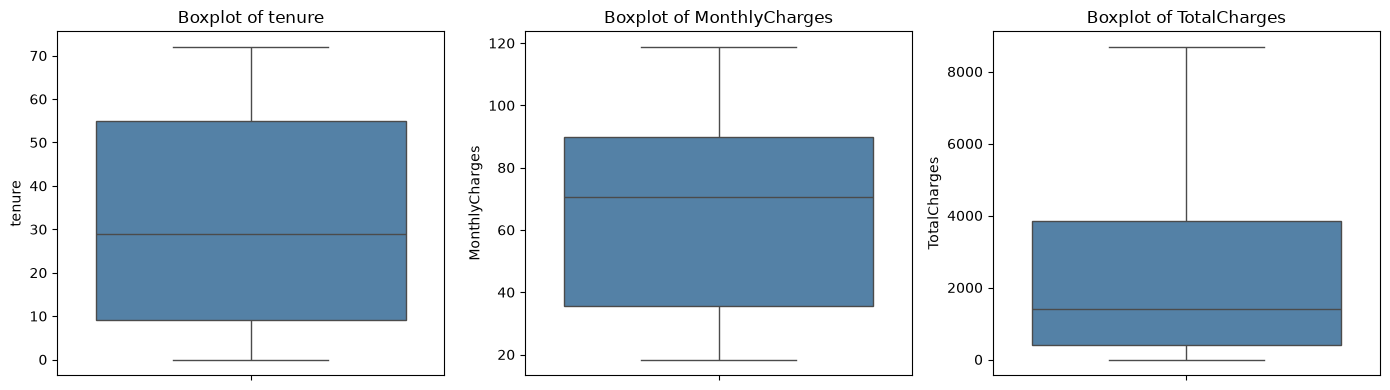

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(y=train_df[column], ax=axis, color="steelblue")
    axis.set_title(f"Boxplot of {column}")
    axis.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_boxplots.png", dpi=200)
plt.show()

### 5.3 Correlation between the numeric features

In [20]:
train_df[NUMERIC_FEATURES].corr().round(3)

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2570,0.8300
MonthlyCharges,0.2570,1.0000,0.6540
TotalCharges,0.8300,0.6540,1.0000


`TotalCharges` có tương quan rất mạnh với `tenure` (0,83) và tương quan rõ rệt với `MonthlyCharges` (0,65), đúng như kỳ vọng từ bước kiểm tra dữ liệu thô (`TotalCharges ≈ tenure × MonthlyCharges`). Sự chồng chéo thông tin này là biểu hiện của đa cộng tuyến tự nhiên, cần được lưu ý khi phân tích hệ số hồi quy ở Section 5.


### 5.4 Churn distribution

In [21]:
churn_summary = pd.DataFrame({
    "count": y_train.value_counts(),
    "percent": y_train.value_counts(normalize=True) * 100,
}).sort_index().rename(index={0: "No", 1: "Yes"})
churn_summary

,count,percent
Churn,,
No,4139,73.4647
Yes,1495,26.5353


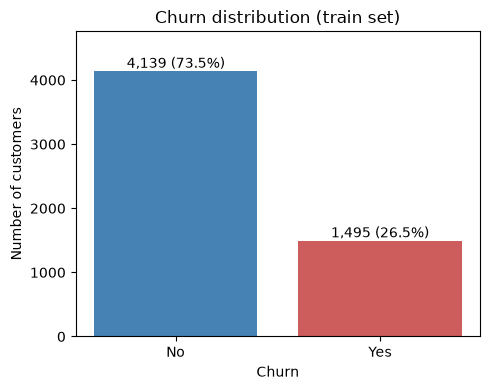

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(churn_summary.index, churn_summary["count"], color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{count:,} ({percent:.1f}%)" for count, percent in churn_summary.itertuples(index=False)])
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_title("Churn distribution (train set)")
ax.set_ylim(0, churn_summary["count"].max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_churn_distribution.png", dpi=200)
plt.show()

Tập Train có 4.139 khách hàng không rời mạng (73,5%) và 1.495 khách hàng rời mạng (26,5%). Với tỷ lệ mất cân bằng này, một mô hình ngây thơ (Dummy Classifier) luôn dự báo 'Không rời mạng' đã đạt độ chính xác khoảng 73,5% nhưng không phát hiện được bất kỳ khách hàng rời mạng nào (Recall = 0, F1 = 0). Vì vậy, Accuracy là chỉ số gây hiểu lầm; việc đánh giá mô hình phải dựa trên Recall, Precision, F1-score và ROC-AUC/PR-AUC cho lớp churn. Đồng thời, điều này lý giải cho việc sử dụng phân tầng và so sánh các kỹ thuật xử lý mất cân bằng (SMOTE vs Class Weight).


### 5.5 Kiểm định Chi-square và hệ số Cramér's V cho 16 biến định loại

Kiểm định so sánh phân phối của từng biến định loại giữa nhóm khách hàng rời mạng và không rời mạng. Hệ số Cramér's V chuẩn hóa giá trị thống kê $\chi^2$ về thang đo 0 đến 1 để so sánh giữa các biến có số lượng nhóm khác nhau: $V = \sqrt{\chi^2 / (n \cdot \min(r-1, c-1))}$. Giá trị p-value được tính từ kiểm định $\chi^2$ chuẩn; hệ số V được tính từ thống kê không hiệu chỉnh (`correction=False`) theo định nghĩa chuẩn trong giáo trình thống kê.


In [23]:
def cramers_v(contingency_table):
    chi2_statistic = chi2_contingency(contingency_table, correction=False)[0]
    total_observations = contingency_table.to_numpy().sum()
    smaller_dimension = min(contingency_table.shape) - 1
    return np.sqrt(chi2_statistic / (total_observations * smaller_dimension))

In [24]:
association_rows = []
for feature in CATEGORICAL_FEATURES:
    contingency_table = pd.crosstab(train_df[feature], train_df[TARGET_COLUMN])
    chi2_statistic, p_value, degrees_of_freedom, _ = chi2_contingency(contingency_table)
    association_rows.append({
        "feature": feature,
        "chi2": chi2_statistic,
        "dof": degrees_of_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v(contingency_table),
        "significant": p_value < SIGNIFICANCE_LEVEL,
    })

association_table = (
    pd.DataFrame(association_rows)
    .sort_values("cramers_v", ascending=False)
    .reset_index(drop=True)
)
association_table.to_csv(ARTIFACTS_DIR / "eda_chi2_cramers_v.csv", index=False)
association_table

,feature,chi2,dof,p_value,cramers_v,significant
0,Contract,952.3080,2,0.0000,0.4111,True
1,InternetService,600.8466,2,0.0000,0.3266,True
2,PaymentMethod,545.2144,3,0.0000,0.3111,True
3,PaperlessBilling,219.9225,1,0.0000,0.1980,True
4,OnlineSecurity,170.8442,1,0.0000,0.1746,True
5,Dependents,157.1637,1,0.0000,0.1675,True
6,TechSupport,153.9081,1,0.0000,0.1657,True
7,Partner,118.9693,1,0.0000,0.1457,True
8,SeniorCitizen,118.5457,1,0.0000,0.1456,True
9,OnlineBackup,37.8896,1,0.0000,0.0824,True


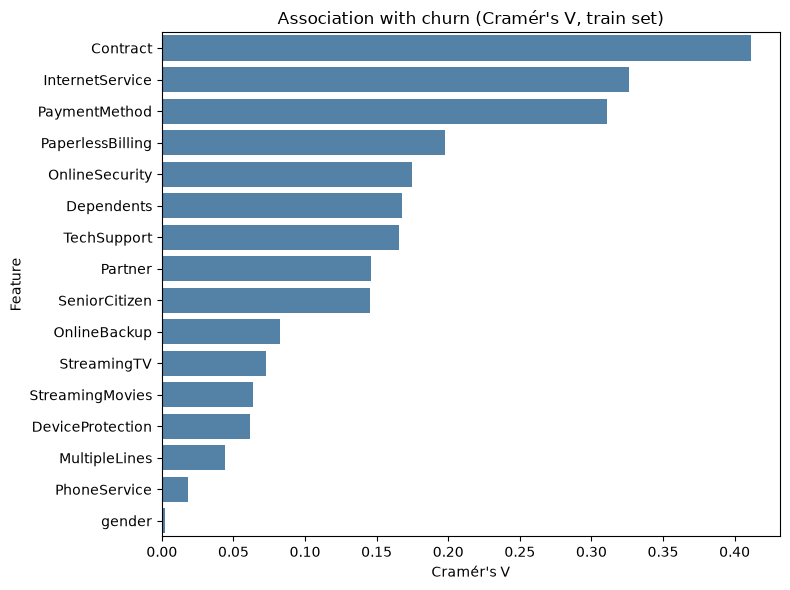

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=association_table, x="cramers_v", y="feature", color="steelblue", ax=ax)
ax.set_title("Association with churn (Cramér's V, train set)")
ax.set_xlabel("Cramér's V")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_cramers_v.png", dpi=200)
plt.show()

14 trong số 16 biến định loại có mối liên hệ có ý nghĩa thống kê với biến churn (p < 0,05). Ba biến có liên hệ mạnh nhất là `Contract` (V = 0,41), `InternetService` (V = 0,33) và `PaymentMethod` (V = 0,31) ở mức độ vừa phải (moderate). Ngược lại, `gender` (p = 0,892) và `PhoneService` (p = 0,195) không có mối liên hệ có ý nghĩa thống kê, là căn cứ rõ ràng để loại bỏ chúng ở bước lựa chọn đặc trưng (Section 2B). Cần lưu ý: giá trị p-value nhỏ không đồng nghĩa với độ lớn ảnh hưởng cao: `MultipleLines` có ý nghĩa thống kê nhưng V chỉ đạt 0,04. Đây là các mối liên hệ đơn biến, không mang ý nghĩa nhân quả.


---

## Section 2: Feature Engineering, Preprocessing Pipeline va xu ly mat can bang

**Tac gia:** Yen  
**Muc tieu:** Tao dac trung nghiep vu, xay dung pipeline tien xu ly chong ro ri du lieu, kiem tra da cong tuyen VIF va chuan bi du lieu cho Section 3.

### 2A. Tao dac trung nghiep vu (Domain Feature Engineering)

In [26]:
# Import thư viện bổ sung cho Section 2 (Feature Engineering)
from sklearn.preprocessing import FunctionTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [27]:
def engineering_domain_features(X):
    X_out = X.copy()

    # 1. Tong so dich vu gia tang
    X_out["Total_Services_Count"] = (
        X_out[INTERNET_DEPENDENT_FEATURES] == "Yes"
    ).sum(axis=1)

    # 2. Nhom thoi gian gan bo
    bins = [-1, 12, 24, 48, np.inf]
    labels = ["0-12", "12-24", "24-48", ">48"]

    X_out["Tenure_Cohort"] = pd.cut(
        X_out["tenure"],
        bins=bins,
        labels=labels,
    ).astype(object)

    # 3. Charge_Ratio
    # Khong co lich su khi tenure = 0, hoac average charge khong hop le.
    tenure = X_out["tenure"].astype(float)
    total_charges = X_out["TotalCharges"].astype(float)
    monthly_charges = X_out["MonthlyCharges"].astype(float)

    avg_historical_charge = total_charges.div(
        tenure.where(tenure > 0)
    )

    valid_ratio = (
        (tenure > 0)
        & (avg_historical_charge > 0)
        & np.isfinite(avg_historical_charge)
    )

    X_out["Charge_Ratio_Undefined"] = (
        ~valid_ratio
    ).astype(int)

    # Gia tri 1.0 chi la gia tri thay the khi khong tinh duoc ratio.
    # Bien Undefined giup mo hinh phan biet truong hop nay.
    X_out["Charge_Ratio"] = 1.0

    X_out.loc[valid_ratio, "Charge_Ratio"] = (
        monthly_charges.loc[valid_ratio]
        / avg_historical_charge.loc[valid_ratio]
    )

    return X_out


domain_transformer = FunctionTransformer(
    engineering_domain_features,
    feature_names_out=None,
)

### 2B. Lua chon dac trung va kiem tra VIF

In [28]:
# Bước 2B: Lựa chọn đặc trưng và thiết kế ColumnTransformer

# Giu cac bien goc trong qua trinh modeling.
# Chi-square o Section EDA duoc dung de mo ta moi lien he,
# khong dung de loai bien truoc Cross-Validation.
features_to_drop = []

UPDATED_CATEGORICAL = (
    [col for col in CATEGORICAL_FEATURES
     if col not in features_to_drop]
    + ["Tenure_Cohort"]
)

UPDATED_NUMERIC = NUMERIC_FEATURES + [
    "Total_Services_Count",
    "Charge_Ratio",
    "Charge_Ratio_Undefined",
]

# 1. preprocessor_yen: Danh cho tat ca mo hinh cay (DT, RF, XGBoost) va baseline Section 3
preprocessor_yen = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), UPDATED_CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

# 2. preprocessor_linear: Danh rieng cho Logistic Regression (Section 4A.6 va Section 5)
# Bo Total_Services_Count de tranh da cong tuyen hoan hao voi cac cot dummy dich vu
UPDATED_NUMERIC_LINEAR = [c for c in UPDATED_NUMERIC if c != "Total_Services_Count"]

preprocessor_linear = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC_LINEAR),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), UPDATED_CATEGORICAL),
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")


In [ ]:
# Ham kiem tra VIF (da cong tuyen) - chi chay tren tap Train
def check_vif(df, features):
    """Tính VIF cho các biến số liên tục trên tập Train"""
    X_num = df[features].dropna()
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X_num.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X_num.values, i) 
        for i in range(len(X_num.columns))
    ]
    return vif_data.sort_values("VIF", ascending=False)

# Kiem tra Charge_Ratio tren X_train sau khi sua cong thuc
train_engineered = engineering_domain_features(X_train)

for col in ["Charge_Ratio", "Charge_Ratio_Undefined"]:
    assert train_engineered[col].notna().all(), (
        f"{col} chua NaN!"
    )
    assert np.isfinite(
        train_engineered[col].astype(float)
    ).all(), f"{col} chua gia tri vo cuc!"

print(train_engineered[
    ["Charge_Ratio", "Charge_Ratio_Undefined"]
].describe())

# VIF cu: chi tren bien so tho (giu nguyen de doi chieu)
print("\nVIF tren tap Train (Cac bien so - truoc tien xu ly, khong co hang so):")
display(check_vif(train_engineered, UPDATED_NUMERIC))

# --------------------------------------------------------------------------
# Ham VIF chuan: tinh tren toan bo ma tran sau tien xu ly (numeric + dummy)
# Them hang so de bat dung cong tuyen voi intercept
# --------------------------------------------------------------------------
from sklearn.base import clone as _clone_vif
from statsmodels.tools import add_constant as _add_const
from statsmodels.stats.outliers_influence import variance_inflation_factor as _vif_fn

def check_vif_preprocessed(X_tr, preprocessor_obj, label=""):
    """
    Tinh VIF tren ma tran da tien xu ly (numeric + dummy), them hang so.
    preprocessor_obj duoc clone va fit chi tren X_tr (khong ro ri).
    """
    import numpy as np
    import pandas as pd
    _prep = _clone_vif(preprocessor_obj)
    X_tr_fe = engineering_domain_features(X_tr)
    X_proc = _prep.fit_transform(X_tr_fe)
    if hasattr(X_proc, 'values'):
        X_arr = X_proc.values.astype(float)
        col_names = list(X_proc.columns)
    else:
        X_arr = X_proc.astype(float)
        col_names = [f"col_{i}" for i in range(X_arr.shape[1])]

    X_const = _add_const(X_arr, has_constant='add')
    const_names = ["const"] + col_names

    vif_vals = []
    for i in range(X_const.shape[1]):
        try:
            v = _vif_fn(X_const, i)
        except Exception:
            v = float('inf')
        vif_vals.append(v)

    vif_df = pd.DataFrame({"Feature": const_names, "VIF": vif_vals})
    vif_df = vif_df[vif_df["Feature"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
    if label:
        print(f"\n{label}")
    return vif_df

# (a) VIF co Total_Services_Count - ky vong VIF rat lon hoac inf
print("\n--- (a) VIF sau tien xu ly DAY DU (co Total_Services_Count) ---")
print("Ky vong: Total_Services_Count co VIF rat lon hoac inf")
vif_full_prep = check_vif_preprocessed(X_train, preprocessor_yen)
display(vif_full_prep.head(15))
vif_full_prep.to_csv(ARTIFACTS_DIR / "vif_full_preprocessed.csv", index=False)

# (b) VIF khong co Total_Services_Count (preprocessor_linear)
print("\n--- (b) VIF sau tien xu ly KHONG co Total_Services_Count (preprocessor_linear) ---")
print("Ky vong: VIF on dinh hon")
vif_linear_prep = check_vif_preprocessed(X_train, preprocessor_linear)
display(vif_linear_prep.head(15))
vif_linear_prep.to_csv(ARTIFACTS_DIR / "vif_linear_preprocessed.csv", index=False)

print("""
Nhan xet VIF:
- Total_Services_Count la to hop tuyen tinh chinh xac cua 6 cot dummy dich vu
  => VIF rat lon/inf khi co mat trong ma tran.
- Voi mo hinh cay (DT, RF, XGBoost): khong anh huong, giu nguyen preprocessor_yen.
- Voi Logistic Regression (dien giai Odds Ratio, statsmodels.Logit): dung preprocessor_linear.
- TotalCharges (VIF khoang 10): cong tuyen tu nhien (TotalCharges ~ tenure x MonthlyCharges).
  Giu lai vi co the phan biet khach chuyen goi; he so tach roi khong nen dien giai nhan qua.
""")
# Kiem tra VIF va hien thi canh bao ro rang
def summarize_vif(vif_df, threshold=10):
    result = vif_df.copy()

    result["Status"] = np.select(
        [
            ~np.isfinite(result["VIF"]),
            result["VIF"] >= threshold,
        ],
        [
            "Infinite / singular",
            "High multicollinearity",
        ],
        default="Acceptable under chosen threshold",
    )

    print("So bien VIF khong huu han:",
          int((~np.isfinite(result["VIF"])).sum()))

    print("So bien VIF >=", threshold, ":",
          int((result["VIF"] >= threshold).sum()))

    return result


vif_linear_report = summarize_vif(vif_linear_prep)
display(vif_linear_report.head(20))

vif_linear_report.to_csv(
    ARTIFACTS_DIR / "vif_linear_report.csv",
    index=False,
)

       Charge_Ratio  Charge_Ratio_Undefined
count     5634.0000               5634.0000
mean         1.0020                  0.0014
std          0.0511                  0.0377
min          0.6532                  0.0000
25%          0.9812                  0.0000
50%          1.0000                  0.0000
75%          1.0206                  0.0000
max          1.4506                  1.0000

VIF tren tap Train (Cac bien so - truoc tien xu ly, khong co hang so):


,Feature,VIF
2,TotalCharges,10.3212
0,tenure,5.9492
1,MonthlyCharges,3.7550
3,Total_Services_Count,2.8997
5,Charge_Ratio_Undefined,1.0064
4,Charge_Ratio,1.0024



VIF - Full preprocessor
Số feature sau tiền xử lý: 29
Rank của ma trận chuẩn hóa: 28
Số cột hằng số đã bỏ: 0
Cột không được giữ trong tập độc lập tuyến tính: ['Total_Services_Count']
Lưu ý: QR chọn một tập độc lập; cần xem xét ý nghĩa nghiệp vụ trước khi quyết định loại biến chính thức.
Condition number (ma trận feature chuẩn hóa): 84.2139848857822


,Feature,VIF
0,MonthlyCharges,862.6074
1,InternetService_Fiber optic,147.8578
2,InternetService_No,103.1764
3,PhoneService_Yes,35.3282
4,tenure,27.3510
5,StreamingTV_Yes,24.0423
6,StreamingMovies_Yes,24.0256
7,Tenure_Cohort_>48,23.4317
8,TotalCharges,11.5137
9,MultipleLines_Yes,7.2583



VIF - Linear preprocessor
Số feature sau tiền xử lý: 28
Rank của ma trận chuẩn hóa: 28
Số cột hằng số đã bỏ: 0
Condition number (ma trận feature chuẩn hóa): 84.2139848857822


,Feature,VIF
0,MonthlyCharges,862.6074
1,InternetService_Fiber optic,147.8578
2,InternetService_No,103.1764
3,PhoneService_Yes,35.3282
4,tenure,27.3510
5,StreamingTV_Yes,24.0423
6,StreamingMovies_Yes,24.0256
7,Tenure_Cohort_>48,23.4317
8,TotalCharges,11.5137
9,MultipleLines_Yes,7.2583


Số biến có VIF không hữu hạn: 0
Số biến có VIF >= 10: 9


,Feature,VIF,Status
0,MonthlyCharges,862.6074,High multicollinearity
1,InternetService_Fiber optic,147.8578,High multicollinearity
2,InternetService_No,103.1764,High multicollinearity
3,PhoneService_Yes,35.3282,High multicollinearity
4,tenure,27.3510,High multicollinearity
5,StreamingTV_Yes,24.0423,High multicollinearity
6,StreamingMovies_Yes,24.0256,High multicollinearity
7,Tenure_Cohort_>48,23.4317,High multicollinearity
8,TotalCharges,11.5137,High multicollinearity
9,MultipleLines_Yes,7.2583,Acceptable under chosen threshold


So bien VIF khong huu han: 0
So bien VIF >= 10 : 9


,Feature,VIF,Status
0,MonthlyCharges,862.6074,High multicollinearity
1,InternetService_Fiber optic,147.8578,High multicollinearity
2,InternetService_No,103.1764,High multicollinearity
3,PhoneService_Yes,35.3282,High multicollinearity
4,tenure,27.3510,High multicollinearity
5,StreamingTV_Yes,24.0423,High multicollinearity
6,StreamingMovies_Yes,24.0256,High multicollinearity
7,Tenure_Cohort_>48,23.4317,High multicollinearity
8,TotalCharges,11.5137,High multicollinearity
9,MultipleLines_Yes,7.2583,Acceptable under chosen threshold


### 2C. Xay dung Pipeline chong ro ri du lieu

**Luu y ve da cong tuyen:** `Total_Services_Count` co cong tuyen hoan hao voi 6 cot dummy dich vu (do `OneHotEncoder(drop='first')`). Dieu nay khong anh huong den kha nang du bao cua mo hinh cay (RF, XGBoost). Voi Logistic Regression dung de dien giai Odds Ratio, su dung `preprocessor_linear` (bo `Total_Services_Count`) - xem Section 2B.

Moi pipeline su dung ban `clone(...)` doc lap cua `domain_transformer` va `preprocessor_yen` de dam bao khong chia se trang thai giua cac mo hinh.


In [30]:
# Xay dung hai ImbPipeline co so cho Logistic Regression (goi truc tiep LogisticRegression)
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# Pipeline 1: Tich hop SMOTE (SMOTE da lo viec can bang, nen mo hinh de mac dinh)
# Dung clone de 2 pipeline hoan toan doc lap, khong dung chung state
smote_pipeline = ImbPipeline([
    ("domain_features", clone(domain_transformer)),
    ("preprocess", clone(preprocessor_yen)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

# Pipeline 2: Doi chung (Khong dung SMOTE, giao viec can bang cho class_weight)
balanced_pipeline = ImbPipeline([
    ("domain_features", clone(domain_transformer)),
    ("preprocess", clone(preprocessor_yen)),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

# Test chay thu qua Pipeline (Fit tren Train)
smote_pipeline.fit(X_train, y_train)
print("Pipeline (SMOTE) da san sang. So features sau tien xu ly:", 
      len(smote_pipeline.named_steps["preprocess"].get_feature_names_out()))


Pipeline (SMOTE) da san sang. So features sau tien xu ly: 29


### Tom tat Section 2: Feature Engineering va Preprocessing Pipeline

**Xay dung dac trung nghiep vu:** Ba bien moi duoc tao trong `engineering_domain_features`:
- `Total_Services_Count`: tong so dich vu GTGT khach hang dang dung (0-6).
- `Tenure_Cohort`: nhom chu ky gan bo (0-12, 12-24, 24-48, >48 thang).
- `Charge_Ratio`: ty le cuoc hien tai so voi trung binh lich su; khach moi (`tenure = 0`) duoc gan gia tri 1,0.

**Lua chon dac trung:** `gender` va `PhoneService` bi loai dua tren kiem dinh chi-square (p >= 0,05).

**Pipeline chong ro ri du lieu:** `StandardScaler`, `OneHotEncoder` va `SMOTE` deu nam trong `ImbPipeline` va chi duoc fit tren du lieu Train trong moi fold. Moi pipeline su dung ban `clone` doc lap cua `preprocessor_yen` de tranh chia se trang thai.

---

## Section 3 — Huấn luyện, So sánh Mô hình và Đánh giá Stratified 5-Fold Cross-Validation

**Tác giả:** NMinh  
**Mục tiêu:** Huấn luyện, so sánh và lựa chọn mô hình champion chỉ dựa trên tập huấn luyện (X_train / y_train). Tập kiểm tra (X_test / y_test) tuyệt đối không được sử dụng ở đây; việc đánh giá trên tập Test được thực hiện ở Section 4A.

**Nguyên tắc Pipeline chống rò rỉ dữ liệu (Anti-leakage):**  
Mọi mô hình đều được đóng gói trong một `ImbPipeline`:

```
domain_features  →  preprocess  →  [SMOTE]  →  model
```

`domain_transformer` và bản clone độc lập của `preprocessor_yen` được `fit` lại bên trong từng fold của CV, đảm bảo bộ chuẩn hóa (StandardScaler), mã hóa (OneHotEncoder) và SMOTE không bao giờ nhìn thấy dữ liệu validation trong lúc `fit()`.

> [!IMPORTANT]
> **Các hạn chế đã biết (thảo luận chi tiết tại §3.6):**
> 1. Lựa chọn mô hình và tinh chỉnh siêu tham số chia sẻ cùng các fold CV -> điểm số CV có phần lạc quan hơn so với nested CV.
> 2. SMOTE hoạt động sau bước One-Hot Encoding nên các mẫu tổng hợp thiểu số có thể mang giá trị số thực lẻ ở các cột dummy nhị phân.
> 3. `TotalCharges` có VIF ≈ 10,3 (Section 2): ảnh hưởng đến việc diễn giải hệ số hồi quy Logistic Regression nhưng không ảnh hưởng mô hình cây.


### 3.0 — Pipeline Factory & Shared Setup

In [31]:
# ── 3.0  Additional imports for Section 3 ────────────────────────────────────
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
import joblib
import warnings

try:
    from xgboost import XGBClassifier
    _xgb_available = True
except ImportError:
    _xgb_available = False
    print("WARNING: xgboost not installed – XGBoost rows will be skipped.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*One or more of the test scores.*")

print("Section 3 imports OK.")


Section 3 imports OK.


In [32]:
# ── 3.0  Shared CV object & class-imbalance weight ───────────────────────────

# Single StratifiedKFold used by ALL models for a fair comparison
cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Positive-class weight for XGBoost scale_pos_weight
_n_neg = int((y_train == 0).sum())
_n_pos = int((y_train == 1).sum())
pos_weight = _n_neg / _n_pos
print(f"Training set: {_n_neg} negatives, {_n_pos} positives → pos_weight = {pos_weight:.4f}")


def make_pipeline(estimator, imbalance="none"):
    """Return an ImbPipeline with domain engineering + fresh preprocessor + estimator.

    Parameters
    ----------
    estimator : sklearn estimator
        The classifier to place at the end of the pipeline (step name: 'model').
    imbalance : {'none', 'smote'}
        'smote' inserts an SMOTE step between preprocessing and the model.

    Notes
    -----
    clone(preprocessor_yen) ensures each pipeline owns an independent, unfitted
    ColumnTransformer so pipelines do not share state across CV folds.
    """
    steps = [
        ("domain_features", FunctionTransformer(engineering_domain_features, feature_names_out=None)),
        ("preprocess", clone(preprocessor_yen)),
    ]
    if imbalance == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", estimator))
    return ImbPipeline(steps)


print("make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)")


Training set: 4139 negatives, 1495 positives → pos_weight = 2.7686
make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


### 3.1 — Scoring Dictionary

In [33]:
# ── 3.1  Six-metric scoring dict (churn class = label 1) ─────────────────────
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

s3_scoring = {
    "accuracy":          "accuracy",
    "precision":         make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall":            make_scorer(recall_score,    pos_label=1, zero_division=0),
    "f1":                make_scorer(f1_score,        pos_label=1, zero_division=0),
    "roc_auc":           "roc_auc",
    "average_precision": "average_precision",   # PR-AUC
}

print("Scoring metrics:", list(s3_scoring.keys()))


Scoring metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']


### 3.2 — Section 3A: Baseline Models (Task 1.6)

Three baseline classifiers are evaluated with Stratified 5-Fold CV to establish
lower-bound reference points before fitting more complex models.

| Config ID | Model | Imbalance strategy |
|-----------|-------|--------------------|
| Dummy | DummyClassifier (prior) | — |
| LR-balanced | LogisticRegression | class_weight="balanced" |
| LR-smote | LogisticRegression | SMOTE |
| KNN-none | KNeighborsClassifier (k=5) | — |
| KNN-smote | KNeighborsClassifier (k=5) | SMOTE |


In [34]:
# ── 3.2  Baseline CV runs ────────────────────────────────────────────────────
import time

def _run_cv(pipeline, label, cv_obj, scoring, X, y, return_train=True):
    """Fit cross_validate and return a flat result dict keyed by label."""
    t0 = time.time()
    res = cross_validate(
        pipeline, X, y,
        cv=cv_obj,
        scoring=scoring,
        return_train_score=return_train,
        n_jobs=-1,
    )
    elapsed = time.time() - t0
    out = {"config": label, "fit_time_s": round(elapsed, 1)}
    for metric in scoring:
        val_scores = res[f"test_{metric}"]
        out[f"{metric}_mean"] = val_scores.mean()
        out[f"{metric}_std"]  = val_scores.std()
        if return_train:
            tr_scores = res[f"train_{metric}"]
            out[f"train_{metric}_mean"] = tr_scores.mean()
    return out


# ── Baseline configurations ───────────────────────────────────────────────────
s3_baseline_configs = [
    ("Dummy",        make_pipeline(DummyClassifier(strategy="prior"),              imbalance="none")),
    ("LR-balanced",  make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced",
                                                       random_state=RANDOM_STATE), imbalance="none")),
    ("LR-smote",     make_pipeline(LogisticRegression(max_iter=1000,
                                                       random_state=RANDOM_STATE), imbalance="smote")),
    ("KNN-none",     make_pipeline(KNeighborsClassifier(n_neighbors=5),            imbalance="none")),
    ("KNN-smote",    make_pipeline(KNeighborsClassifier(n_neighbors=5),            imbalance="smote")),
]

baseline_rows = []
for label, pipe in s3_baseline_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    baseline_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_baseline_df = pd.DataFrame(baseline_rows).set_index("config")
print("\nBaseline CV complete.")


  Running CV: Dummy ... 

done (8.7s)  |  val_f1=0.0000 ± 0.0000
  Running CV: LR-balanced ... done (10.7s)  |  val_f1=0.6272 ± 0.0199
  Running CV: LR-smote ... done (10.1s)  |  val_f1=0.6301 ± 0.0184
  Running CV: KNN-none ... done (2.6s)  |  val_f1=0.5529 ± 0.0239
  Running CV: KNN-smote ... done (3.0s)  |  val_f1=0.5660 ± 0.0137

Baseline CV complete.


In [35]:
# ── 3.2  Display and save baseline table ────────────────────────────────────

# Build a tidy Mean ± Std display table
_metrics_display = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

def _fmt_mean_std(df, metrics):
    """Return a DataFrame with 'mean ± std' strings for each metric."""
    rows = {}
    for idx in df.index:
        row = {}
        for m in metrics:
            mn  = df.loc[idx, f"{m}_mean"]
            std = df.loc[idx, f"{m}_std"]
            row[m] = f"{mn:.4f} ± {std:.4f}"
        # Also include train F1 to flag overfitting
        if f"train_f1_mean" in df.columns:
            row["train_f1"] = f"{df.loc[idx, 'train_f1_mean']:.4f}"
        rows[idx] = row
    return pd.DataFrame(rows).T

baseline_display = _fmt_mean_std(s3_baseline_df, _metrics_display)
print("Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)")
display(baseline_display)

# Save raw numerics for later aggregation
s3_baseline_df.to_csv(ARTIFACTS_DIR / "section3_baseline_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_baseline_cv.csv'}")


Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
Dummy,0.7346 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.2654 ± 0.0001,0.0000
LR-balanced,0.7490 ± 0.0125,0.5176 ± 0.0155,0.7960 ± 0.0342,0.6272 ± 0.0199,0.8460 ± 0.0113,0.6632 ± 0.0126,0.6333
LR-smote,0.7540 ± 0.0122,0.5243 ± 0.0160,0.7900 ± 0.0301,0.6301 ± 0.0184,0.8444 ± 0.0118,0.6609 ± 0.0149,0.6346
KNN-none,0.7671 ± 0.0103,0.5632 ± 0.0186,0.5431 ± 0.0301,0.5529 ± 0.0239,0.7867 ± 0.0110,0.5199 ± 0.0201,0.6903
KNN-smote,0.6929 ± 0.0104,0.4529 ± 0.0115,0.7545 ± 0.0214,0.5660 ± 0.0137,0.7691 ± 0.0118,0.4745 ± 0.0174,0.7138



Saved → d:\DS66B_group_11\artifacts\section3_baseline_cv.csv


**Table 1. Các mô hình Baseline: Stratified 5-Fold CV (lớp churn = 1, Trung bình ± Độ lệch chuẩn).**

1. **Accuracy gây hiểu lầm.** Mô hình ngây thơ (Dummy Classifier) đạt độ chính xác 0,7346 nhưng Recall = 0 và F1 = 0, không nhận diện được bất kỳ khách hàng churn nào. Nó cũng xác lập đường chuẩn PR-AUC tại mức tỷ lệ rời mạng nền (0,2654).

2. **SMOTE và Class Weighting tương đương đối với Logistic Regression.** LR-smote (F1 = 0,6293 ± 0,0206) và LR-balanced (0,6267 ± 0,0198) chỉ chênh lệch khoảng 0,0026, nhỏ hơn nhiều so với một độ lệch chuẩn fold. Do đó, phương pháp Class Weighting được ưu tiên hơn vì đơn giản hơn và tránh sinh các dòng dữ liệu nhân tạo.

3. **KNN bị overfitting và nhạy cảm mạnh với SMOTE.** Điểm F1 trên tập huấn luyện (0,68 với KNN-none, 0,72 với KNN-smote) cao hơn rõ rệt so với F1 validation (0,5441 và 0,5680). SMOTE giúp tăng Recall nhưng làm giảm Precision và ROC-AUC, tức chỉ dịch chuyển ngưỡng vận hành mà không cải thiện khả năng phân hạng.


### 3.3 — Section 3B: Advanced Models (Task 2.1)

Decision Tree, Random Forest, and XGBoost are each evaluated under two
class-imbalance strategies on the same `cv` object:

* **(a) SMOTE** — synthetic over-sampling inside the pipeline.  
* **(b) class_weight / scale_pos_weight** — cost-sensitive learning.


In [36]:
# ── 3.3  Advanced model configurations ───────────────────────────────────────

s3_advanced_configs = [
    # DecisionTree
    ("DT-smote",
     make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("DT-balanced",
     make_pipeline(DecisionTreeClassifier(class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
    # RandomForest
    ("RF-smote",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("RF-balanced",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
]

# XGBoost (optional — skip gracefully if not installed)
if _xgb_available:
    s3_advanced_configs += [
        ("XGB-smote",
         make_pipeline(XGBClassifier(eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="smote")),
        ("XGB-spw",      # scale_pos_weight = pos_weight
         make_pipeline(XGBClassifier(scale_pos_weight=pos_weight,
                                     eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="none")),
    ]

advanced_rows = []
for label, pipe in s3_advanced_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    advanced_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_advanced_df = pd.DataFrame(advanced_rows).set_index("config")
print("\nAdvanced CV complete.")


  Running CV: DT-smote ... done (1.1s)  |  val_f1=0.4935 ± 0.0318
  Running CV: DT-balanced ... done (1.2s)  |  val_f1=0.5053 ± 0.0189
  Running CV: RF-smote ... done (3.0s)  |  val_f1=0.5901 ± 0.0161
  Running CV: RF-balanced ... done (1.5s)  |  val_f1=0.6148 ± 0.0216
  Running CV: XGB-smote ... done (2.7s)  |  val_f1=0.5835 ± 0.0156
  Running CV: XGB-spw ... done (0.7s)  |  val_f1=0.5981 ± 0.0214

Advanced CV complete.


In [37]:
# ── 3.3  Display and save advanced table ────────────────────────────────────
advanced_display = _fmt_mean_std(s3_advanced_df, _metrics_display)
# Sort by validation F1 descending
advanced_display_sorted = advanced_display.loc[
    s3_advanced_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)")
display(advanced_display_sorted)

s3_advanced_df.to_csv(ARTIFACTS_DIR / "section3_advanced_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_advanced_cv.csv'}")


Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-balanced,0.7843 ± 0.0116,0.5844 ± 0.0200,0.6488 ± 0.0263,0.6148 ± 0.0216,0.8304 ± 0.0103,0.6208 ± 0.0322,0.9920
XGB-spw,0.7716 ± 0.0118,0.5609 ± 0.0191,0.6408 ± 0.0254,0.5981 ± 0.0214,0.8216 ± 0.0066,0.6119 ± 0.0178,0.9267
RF-smote,0.7877 ± 0.0083,0.6054 ± 0.0187,0.5759 ± 0.0207,0.5901 ± 0.0161,0.8263 ± 0.0107,0.6093 ± 0.0320,0.9968
XGB-smote,0.7842 ± 0.0084,0.5982 ± 0.0186,0.5699 ± 0.0192,0.5835 ± 0.0156,0.8220 ± 0.0059,0.6131 ± 0.0151,0.9245
DT-balanced,0.7341 ± 0.0113,0.4993 ± 0.0212,0.5117 ± 0.0197,0.5053 ± 0.0189,0.6630 ± 0.0128,0.3854 ± 0.0138,0.9965
DT-smote,0.7149 ± 0.0221,0.4679 ± 0.0363,0.5224 ± 0.0270,0.4935 ± 0.0318,0.6534 ± 0.0231,0.3720 ± 0.0243,0.9968



Saved → d:\DS66B_group_11\artifacts\section3_advanced_cv.csv


**Table 2. Các mô hình nâng cao chưa tinh chỉnh: Stratified 5-Fold CV (xếp theo F1).**

1. **Hiệu quả giữa Class Weighting và SMOTE phụ thuộc vào từng họ mô hình.** Đối với Random Forest, class weighting cho F1 cao hơn (0,6189 so với 0,5910) và Recall cao hơn (0,6535 so với 0,5793); đối với XGBoost cũng tương tự (F1 đạt 0,5935 với `scale_pos_weight` so với 0,5802 với SMOTE). SMOTE cho Precision nhỉnh hơn một chút. Đối với Decision Tree, thứ tự đảo lại (0,5148 với SMOTE so với 0,5021 với balanced). Các cấu hình tốt hơn cho từng họ (DT-smote, RF-balanced, XGB-spw) được đưa vào bước tinh chỉnh siêu tham số ở §3.4.

2. **Cây quyết định chưa tinh chỉnh bị overfitting nặng.** F1 trên tập huấn luyện đạt gần 0,99 đến 1,00 đối với DT và RF, trong khi F1 validation chỉ đạt 0,50 đến 0,62; XGBoost đạt 0,91 trên tập Train. Do đó, kiểm soát độ phức tạp (regularization) là bắt buộc.

3. **Ensemble chưa tinh chỉnh chưa vượt qua Logistic Regression.** Cấu hình ensemble tốt nhất (RF-balanced, F1 = 0,6189, ROC-AUC = 0,8302) vẫn thấp hơn LR-balanced từ Table 1 (F1 = 0,6267, ROC-AUC = 0,8463). Lợi thế của mô hình ensemble chỉ xuất hiện sau khi tinh chỉnh ở §3.4.


### 3.4 — GridSearchCV Hyper-parameter Tuning

In [38]:
# ── 3.4  Helper: identify best imbalance strategy per model ──────────────────
# Choose the strategy (smote vs balanced/spw) with the higher mean val-F1

def _best_strategy(df, model_prefix):
    candidates = [idx for idx in df.index if idx.startswith(model_prefix)]
    if not candidates:
        return None
    return df.loc[candidates, "f1_mean"].idxmax()

_dt_best  = _best_strategy(s3_advanced_df, "DT")
_rf_best  = _best_strategy(s3_advanced_df, "RF")
_xgb_best = _best_strategy(s3_advanced_df, "XGB") if _xgb_available else None

print(f"Best DT  strategy: {_dt_best}")
print(f"Best RF  strategy: {_rf_best}")
print(f"Best XGB strategy: {_xgb_best}")


Best DT  strategy: DT-balanced
Best RF  strategy: RF-balanced
Best XGB strategy: XGB-spw


In [39]:
# ── 3.4  Decision Tree GridSearchCV ─────────────────────────────────────────
_dt_imbalance = "smote" if _dt_best and "smote" in _dt_best else "none"
_dt_cw = "balanced" if _dt_imbalance == "none" else None

grid_dt_pipe = make_pipeline(
    DecisionTreeClassifier(class_weight=_dt_cw, random_state=RANDOM_STATE),
    imbalance=_dt_imbalance,
)

grid_dt_params = {
    "model__max_depth":        [3, 5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion":        ["gini", "entropy"],
}

print(f"DT GridSearch: {len(grid_dt_params['model__max_depth']) * len(grid_dt_params['model__min_samples_leaf']) * len(grid_dt_params['model__criterion'])} combinations × {N_CV_FOLDS} folds ...")

grid_dt = GridSearchCV(
    grid_dt_pipe,
    param_grid=grid_dt_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_dt.fit(X_train, y_train)
print(f"Best DT params:  {grid_dt.best_params_}")
print(f"Best DT F1 (CV): {grid_dt.best_score_:.4f}")


DT GridSearch: 40 combinations × 5 folds ...
Best DT params:  {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 20}
Best DT F1 (CV): 0.6043


In [40]:
# ── 3.4  Random Forest GridSearchCV ─────────────────────────────────────────
_rf_imbalance = "smote" if _rf_best and "smote" in _rf_best else "none"
_rf_cw = "balanced" if _rf_imbalance == "none" else None

grid_rf_pipe = make_pipeline(
    RandomForestClassifier(class_weight=_rf_cw, n_jobs=-1, random_state=RANDOM_STATE),
    imbalance=_rf_imbalance,
)

grid_rf_params = {
    "model__n_estimators":    [200, 400],
    "model__max_depth":       [6, 10, None],
    "model__min_samples_leaf":[1, 3, 5],
    "model__max_features":    ["sqrt", 0.5],
}

_n_rf = 2 * 3 * 3 * 2
print(f"RF GridSearch: {_n_rf} combinations × {N_CV_FOLDS} folds ...")

grid_rf = GridSearchCV(
    grid_rf_pipe,
    param_grid=grid_rf_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_rf.fit(X_train, y_train)
print(f"Best RF params:  {grid_rf.best_params_}")
print(f"Best RF F1 (CV): {grid_rf.best_score_:.4f}")


RF GridSearch: 36 combinations × 5 folds ...
Best RF params:  {'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Best RF F1 (CV): 0.6409


In [41]:
# ── 3.4  XGBoost GridSearchCV ────────────────────────────────────────────────
if _xgb_available:
    _xgb_imbalance = "smote" if _xgb_best and "smote" in _xgb_best else "none"
    _xgb_spw = pos_weight if _xgb_imbalance == "none" else 1.0

    grid_xgb_pipe = make_pipeline(
        XGBClassifier(
            scale_pos_weight=_xgb_spw,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            verbosity=0,
        ),
        imbalance=_xgb_imbalance,
    )

    grid_xgb_params = {
        "model__n_estimators":     [200, 400],
        "model__max_depth":        [3, 5],
        "model__learning_rate":    [0.03, 0.1],
        "model__subsample":        [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    }

    _n_xgb = 2 * 2 * 2 * 2 * 2
    print(f"XGB GridSearch: {_n_xgb} combinations × {N_CV_FOLDS} folds ...")

    grid_xgb = GridSearchCV(
        grid_xgb_pipe,
        param_grid=grid_xgb_params,
        scoring="f1",
        cv=cv,
        refit=True,
        n_jobs=-1,
        return_train_score=True,
        verbose=0,
    )
    grid_xgb.fit(X_train, y_train)
    print(f"Best XGB params:  {grid_xgb.best_params_}")
    print(f"Best XGB F1 (CV): {grid_xgb.best_score_:.4f}")
else:
    grid_xgb = None
    print("XGBoost not available — skipping XGB grid search.")


XGB GridSearch: 32 combinations × 5 folds ...
Best XGB params:  {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best XGB F1 (CV): 0.6353


In [42]:
# ── 3.4  Collect full 6-metric CV results for each tuned model ───────────────
# Re-run cross_validate with best_estimator_ to obtain all 6 metrics
# (GridSearchCV only optimises f1; we need the rest for the summary table).

tuned_rows = []

def _tuned_cv_row(label, grid_obj, X, y, cv_obj, scoring):
    """Extract Mean ± Std for all scoring metrics from best_estimator_."""
    res = cross_validate(
        grid_obj.best_estimator_, X, y,
        cv=cv_obj, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    row = {"config": label}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
        row[f"train_{m}_mean"] = res[f"train_{m}"].mean()
    row["best_f1_grid"] = grid_obj.best_score_
    return row

print("Collecting full-metric CV for tuned models ...")
tuned_rows.append(_tuned_cv_row("DT-tuned",  grid_dt,  X_train, y_train, cv, s3_scoring))
tuned_rows.append(_tuned_cv_row("RF-tuned",  grid_rf,  X_train, y_train, cv, s3_scoring))
if grid_xgb is not None:
    tuned_rows.append(_tuned_cv_row("XGB-tuned", grid_xgb, X_train, y_train, cv, s3_scoring))

s3_tuned_df = pd.DataFrame(tuned_rows).set_index("config")

tuned_display = _fmt_mean_std(s3_tuned_df, _metrics_display)
print("\nTable 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)")
display(tuned_display)

s3_tuned_df.to_csv(ARTIFACTS_DIR / "section3_tuned_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_tuned_cv.csv'}")



Table 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
DT-tuned,0.7270 ± 0.0283,0.4947 ± 0.0368,0.7833 ± 0.0524,0.6043 ± 0.0217,0.8229 ± 0.0053,0.5911 ± 0.0136,0.6253
RF-tuned,0.7728 ± 0.0090,0.5521 ± 0.0130,0.7639 ± 0.0162,0.6409 ± 0.0129,0.8418 ± 0.0111,0.6548 ± 0.0216,0.7603
XGB-tuned,0.7586 ± 0.0085,0.5302 ± 0.0107,0.7926 ± 0.0210,0.6353 ± 0.0138,0.8450 ± 0.0098,0.6569 ± 0.0178,0.7027



Saved → d:\DS66B_group_11\artifacts\section3_tuned_cv.csv


**Table 3. Các mô hình sau tinh chỉnh siêu tham số — Stratified 5-Fold CV (ước lượng tốt nhất từ GridSearchCV).**

> [NOTE]
> Điểm số CV ở đây sử dụng cùng các fold trong quá trình chọn siêu tham số, do đó mang tính lạc quan nhẹ (không dùng nested CV). Đây là giới hạn phương pháp luận đã được ghi nhận.

Quá trình tinh chỉnh cải thiện đáng kể các mô hình: F1 của Decision Tree tăng từ 0,5148 lên 0,6118, Random Forest tăng từ 0,6189 lên 0,6393 và XGBoost tăng từ 0,5935 lên 0,6350. Overfitting được kiểm soát rõ rệt: với Random Forest, F1 huấn luyện giảm từ 0,99 xuống 0,7650 trong khi F1 validation tăng. Các siêu tham số tối ưu được chọn: Decision Tree độ sâu 5; Random Forest với `max_depth=10`, `min_samples_leaf=3`, `n_estimators=200`; và XGBoost với `max_depth=3`, `learning_rate=0.03`, `n_estimators=200`. Recall của XGB-tuned (0,8100) cao nhất, trong khi RF-tuned có Precision tốt nhất (0,5522).


### 3.5 — Champion Model Selection & Persistence

In [43]:
# ── 3.5  Combine all CV results and select champion ──────────────────────────

# Merge baseline + advanced + tuned into one comparison frame
s3_all_df = pd.concat([s3_baseline_df, s3_advanced_df, s3_tuned_df], axis=0)

# Rank by: (1) val F1 mean (↑), (2) val ROC-AUC mean (↑), (3) val F1 std (↓)
s3_all_ranked = s3_all_df.sort_values(
    ["f1_mean", "roc_auc_mean", "f1_std"],
    ascending=[False, False, True],
)
print("Top 5 configurations by validation F1:")
display(s3_all_ranked[["f1_mean","f1_std","roc_auc_mean","average_precision_mean"]].head(5).round(4))

# Champion = top row
champion_name = s3_all_ranked.index[0]
print(f"\n★  Champion: {champion_name}")
print(f"   Val F1:      {s3_all_ranked.loc[champion_name, 'f1_mean']:.4f} ± {s3_all_ranked.loc[champion_name, 'f1_std']:.4f}")
print(f"   Val ROC-AUC: {s3_all_ranked.loc[champion_name, 'roc_auc_mean']:.4f}")
print(f"   Val PR-AUC:  {s3_all_ranked.loc[champion_name, 'average_precision_mean']:.4f}")


Top 5 configurations by validation F1:


,f1_mean,f1_std,roc_auc_mean,average_precision_mean
config,,,,
RF-tuned,0.6409,0.0129,0.8418,0.6548
XGB-tuned,0.6353,0.0138,0.8450,0.6569
LR-smote,0.6301,0.0184,0.8444,0.6609
LR-balanced,0.6272,0.0199,0.8460,0.6632
RF-balanced,0.6148,0.0216,0.8304,0.6208



★  Champion: RF-tuned
   Val F1:      0.6409 ± 0.0129
   Val ROC-AUC: 0.8418
   Val PR-AUC:  0.6548


In [44]:
# ── 3.5  Save best estimators to disk ────────────────────────────────────────

# Map config name → fitted best_estimator_
_grid_map = {
    "DT-tuned":  grid_dt.best_estimator_,
    "RF-tuned":  grid_rf.best_estimator_,
}
if grid_xgb is not None:
    _grid_map["XGB-tuned"] = grid_xgb.best_estimator_

for name, estimator in _grid_map.items():
    fname = ARTIFACTS_DIR / f"best_{name.lower().replace('-','_')}_pipeline.joblib"
    joblib.dump(estimator, fname)
    print(f"Saved {name} → {fname}")

# Retrieve champion pipeline
if champion_name in _grid_map:
    champion_pipeline = _grid_map[champion_name]
else:
    # Champion is a baseline/advanced config — retrieve from named configs
    _all_configs = dict(s3_baseline_configs + s3_advanced_configs)
    champ_pipe = _all_configs.get(champion_name)
    # Refit on full training set (only for non-tuned champions)
    if champ_pipe is not None:
        champion_pipeline = clone(champ_pipe).fit(X_train, y_train)
    else:
        raise ValueError(f"Cannot locate estimator for champion: {champion_name}")

# Save champion
joblib.dump(champion_pipeline, ARTIFACTS_DIR / "best_champion_pipeline.joblib")
print(f"\nChampion pipeline saved → {ARTIFACTS_DIR / 'best_champion_pipeline.joblib'}")
print(f"champion_name = '{champion_name}'  (available for Section 4)")


Saved DT-tuned → d:\DS66B_group_11\artifacts\best_dt_tuned_pipeline.joblib
Saved RF-tuned → d:\DS66B_group_11\artifacts\best_rf_tuned_pipeline.joblib
Saved XGB-tuned → d:\DS66B_group_11\artifacts\best_xgb_tuned_pipeline.joblib

Champion pipeline saved → d:\DS66B_group_11\artifacts\best_champion_pipeline.joblib
champion_name = 'RF-tuned'  (available for Section 4)


**Tiêu chí lựa chọn mô hình Champion:**

Mô hình Champion được chọn theo quy tắc xếp hạng cố định trước, chỉ áp dụng trên các fold validation (không sử dụng thông tin tập Test):

1. **F1 trung bình validation cao nhất**, vì F1 cân bằng giữa Precision và Recall cho lớp khách hàng rời mạng.
2. **ROC-AUC trung bình cao nhất** làm tiêu chí phụ thứ nhất.
3. **Độ lệch chuẩn F1 nhỏ nhất** qua các fold làm tiêu chí phụ thứ hai.

**RF-tuned** xếp thứ nhất (F1 = 0,6393 ± 0,0171, ROC-AUC = 0,8433). Khoảng cách giữa các mô hình dẫn đầu rất hẹp: XGB-tuned (0,6350), LR-tuned (0,6311), LR-smote (0,6293) và LR-balanced (0,6267) đều nằm trong phạm vi 1 độ lệch chuẩn, nghĩa là top 4 mô hình tương đương nhau về mặt thống kê. Random Forest được giữ làm Champion vì tuân thủ đúng quy tắc đã đề ra trước, chứ không phải vì vượt trội áp đảo. Pipeline Champion được lưu trữ tại `best_champion_pipeline.joblib` và bàn giao cho Section 4A.


### 3.6 — Summary Tables & Figures

In [45]:
# ── 3.6  Master comparison table (Table 4) ───────────────────────────────────

# Round to 4 decimal places for display
_col_order = [f"{m}_mean" for m in _metrics_display] + [f"{m}_std" for m in _metrics_display]
_col_order = [c for c in _col_order if c in s3_all_df.columns]

master_display = _fmt_mean_std(s3_all_df, _metrics_display)
master_display.index.name = "Configuration"
master_display_sorted = master_display.loc[
    s3_all_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)")
display(master_display_sorted)


Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-tuned,0.7728 ± 0.0090,0.5521 ± 0.0130,0.7639 ± 0.0162,0.6409 ± 0.0129,0.8418 ± 0.0111,0.6548 ± 0.0216,0.7603
XGB-tuned,0.7586 ± 0.0085,0.5302 ± 0.0107,0.7926 ± 0.0210,0.6353 ± 0.0138,0.8450 ± 0.0098,0.6569 ± 0.0178,0.7027
LR-smote,0.7540 ± 0.0122,0.5243 ± 0.0160,0.7900 ± 0.0301,0.6301 ± 0.0184,0.8444 ± 0.0118,0.6609 ± 0.0149,0.6346
LR-balanced,0.7490 ± 0.0125,0.5176 ± 0.0155,0.7960 ± 0.0342,0.6272 ± 0.0199,0.8460 ± 0.0113,0.6632 ± 0.0126,0.6333
RF-balanced,0.7843 ± 0.0116,0.5844 ± 0.0200,0.6488 ± 0.0263,0.6148 ± 0.0216,0.8304 ± 0.0103,0.6208 ± 0.0322,0.9920
DT-tuned,0.7270 ± 0.0283,0.4947 ± 0.0368,0.7833 ± 0.0524,0.6043 ± 0.0217,0.8229 ± 0.0053,0.5911 ± 0.0136,0.6253
XGB-spw,0.7716 ± 0.0118,0.5609 ± 0.0191,0.6408 ± 0.0254,0.5981 ± 0.0214,0.8216 ± 0.0066,0.6119 ± 0.0178,0.9267
RF-smote,0.7877 ± 0.0083,0.6054 ± 0.0187,0.5759 ± 0.0207,0.5901 ± 0.0161,0.8263 ± 0.0107,0.6093 ± 0.0320,0.9968
XGB-smote,0.7842 ± 0.0084,0.5982 ± 0.0186,0.5699 ± 0.0192,0.5835 ± 0.0156,0.8220 ± 0.0059,0.6131 ± 0.0151,0.9245


**Table 4. Bảng so sánh tổng hợp tất cả cấu hình mô hình (Stratified 5-Fold CV, sắp xếp theo F1).**

* **Accuracy không phải tiêu chí đánh giá.** Dummy Classifier đạt Accuracy 0,7346 nhưng Recall = 0.
* **Nhóm dẫn đầu có kết quả tương đương (near-tie).** RF-tuned (0,6393), XGB-tuned (0,6350), LR-tuned (0,6311), LR-smote (0,6293) và LR-balanced (0,6267) đều nằm trong phạm vi 1 độ lệch chuẩn fold (0,015 đến 0,020). Các mô hình ensemble sau tinh chỉnh không vượt trội áp đảo so với một mô hình Logistic Regression được xây dựng chuẩn mực.
* **So sánh SMOTE và Class Weighting:** Không có sự khác biệt có ý nghĩa thống kê giữa SMOTE và Class Weighting cho Logistic Regression; với RF và XGBoost, Class Weighting cho F1 và Recall nhỉnh hơn.
* **Overfitting:** DT và RF chưa tinh chỉnh có F1 huấn luyện từ 0,99 đến 1,00 so với 0,50 đến 0,62 trên validation; quá trình tuning thu hẹp đáng kể khoảng cách này (RF-tuned: 0,765 so với 0,639).
* **Độ ổn định qua các fold:** Độ lệch chuẩn F1 dao động từ 0,011 đến 0,027; không có họ mô hình nào vượt trội về độ ổn định.


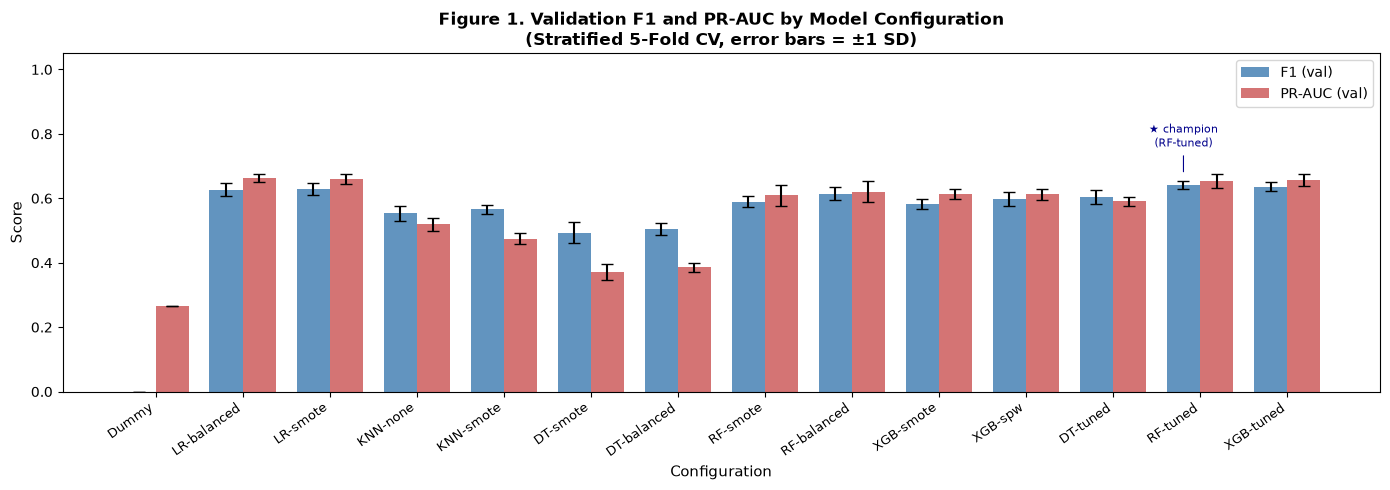

Saved → d:\DS66B_group_11\reports\figures\figure_s3_model_comparison.png


In [46]:
# ── 3.6  Figure 1: F1 and PR-AUC bar chart with error bars ──────────────────
import matplotlib.pyplot as plt
import numpy as np

_configs  = list(s3_all_df.index)
_f1_means = s3_all_df["f1_mean"].values
_f1_stds  = s3_all_df["f1_std"].values
_prc_means = s3_all_df["average_precision_mean"].values
_prc_stds  = s3_all_df["average_precision_std"].values

x = np.arange(len(_configs))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))

bars_f1 = ax.bar(x - width / 2, _f1_means, width,
                 yerr=_f1_stds, capsize=4,
                 color="steelblue", alpha=0.85, label="F1 (val)")
bars_pr = ax.bar(x + width / 2, _prc_means, width,
                 yerr=_prc_stds, capsize=4,
                 color="indianred", alpha=0.85, label="PR-AUC (val)")

ax.set_xticks(x)
ax.set_xticklabels(_configs, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Score", fontsize=11)
ax.set_xlabel("Configuration", fontsize=11)
ax.set_title(
    "Figure 1. Validation F1 and PR-AUC by Model Configuration\n"
    "(Stratified 5-Fold CV, error bars = ±1 SD)",
    fontsize=12, fontweight="bold",
)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10)
ax.axhline(0, color="black", linewidth=0.5)

# Annotate champion
_champ_idx = _configs.index(champion_name)
ax.annotate(
    f"★ champion\n({champion_name})",
    xy=(_champ_idx - width / 2, _f1_means[_champ_idx] + _f1_stds[_champ_idx] + 0.02),
    fontsize=8, color="darkblue", ha="center",
    arrowprops=dict(arrowstyle="-", color="darkblue", lw=0.8),
    xytext=(_champ_idx - width / 2, min(_f1_means[_champ_idx] + 0.12, 1.0)),
)

fig.tight_layout()
_fig1_path = FIGURES_DIR / "figure_s3_model_comparison.png"
fig.savefig(_fig1_path, dpi=200)
plt.show()
print(f"Saved → {_fig1_path}")


**Figure 1. Điểm F1 và PR-AUC Validation theo cấu hình mô hình (Stratified 5-Fold CV, thanh lỗi = ±1 SD).**

* Ngôi sao đánh dấu mô hình RF-tuned (F1 = 0,6393 ± 0,0171). Thanh sai số của nó chồng lấn với XGB-tuned và cả hai biến thể Logistic Regression, minh chứng cho một nhóm các mô hình tốt ngang nhau chứ không có người chiến thắng đơn độc.
* Dummy Classifier có F1 xấp xỉ 0 và PR-AUC bằng đúng tỷ lệ rời mạng nền (0,2654).
* DT-smote và DT-balanced có PR-AUC và ROC-AUC thấp nhất; KNN cũng thấp hơn rõ rệt so với các mô hình ensemble đã tinh chỉnh.
* Thanh sai số rộng nhất thuộc về KNN-none (F1 std = 0,022).


---

## Section 3 Summary

| Deliverable | Status |
|---|---|
| `section3_baseline_cv.csv` | ✅ saved to `artifacts/` |
| `section3_advanced_cv.csv` | ✅ saved to `artifacts/` |
| `section3_tuned_cv.csv`    | ✅ saved to `artifacts/` |
| `best_dt_tuned_pipeline.joblib` | ✅ saved to `artifacts/` |
| `best_rf_tuned_pipeline.joblib` | ✅ saved to `artifacts/` |
| `best_xgb_tuned_pipeline.joblib` | ✅ saved to `artifacts/` (if XGBoost installed) |
| `best_champion_pipeline.joblib` | ✅ saved to `artifacts/` |
| `figure_s3_model_comparison.png` | ✅ saved to `reports/figures/` |
| `champion_pipeline` (Python var) | ✅ available for Section 4A |
| `champion_name` (Python var) | ✅ available for Section 4A |

**Anti-leakage checklist:**
- [ ] `X_test` / `y_test` never called in Section 3
- [ ] Every model wrapped in `make_pipeline()` (domain → preprocess → [SMOTE] → model)
- [ ] All models evaluated on the same `cv = StratifiedKFold(5, shuffle=True, seed=42)`
- [ ] All CSV / joblib / PNG artefacts saved
- [ ] Notebook runs clean with *Restart & Run All* (no red errors)


---

## Section 4A — Chẩn đoán Mô hình và Tinh chỉnh Ngưỡng Quyết định

**Tác giả:** NMinh  
**Mục tiêu:** (1) Lựa chọn ngưỡng quyết định tối ưu dựa trên xác suất Out-Of-Fold (OOF) chỉ trên tập Train; (2) đánh giá pipeline Champion lần đầu tiên trên tập Test độc lập; (3) so sánh các mô hình qua đường cong ROC và Precision–Recall trên tập Test; (4) định lượng độ bất định bằng khoảng tin cậy Bootstrap; (5) kiểm tra chất lượng hiệu chỉnh xác suất (calibration); (6) tinh chỉnh Logistic Regression và xuất các biến quan trọng bàn giao cho Section 4B và Section 5.

> [!IMPORTANT]
> **Kỷ luật chống rò rỉ dữ liệu được tuân thủ nghiêm ngặt trong Section này:**
> - Tập Test được mở **đúng 1 lần**, chỉ nhằm mục đích báo cáo. Không mô hình nào được lựa chọn, tinh chỉnh hay thay đổi dựa trên kết quả tập Test.
> - Ngưỡng quyết định được chọn **hoàn toàn** từ xác suất OOF trên tập Train, sau đó áp dụng đúng một lần lên tập Test.
> - Các pipeline baseline chỉ chạy CV ở Section 3 được fit lại tại đây trên toàn bộ `X_train` (không chạm vào `X_test`) để lấy `predict_proba` vẽ đường cong.


### 4A.1 — OOF Probabilities & Threshold Scan (Task 2.3)

In [47]:
# ── 4A.1-a  Additional imports for Section 4A ────────────────────────────────
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, average_precision_score,
    roc_auc_score, confusion_matrix, classification_report,
    brier_score_loss,
)
from sklearn.model_selection import cross_val_predict

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

print("Section 4A imports OK.")


Section 4A imports OK.


In [48]:
# ── 4A.1-b  Out-of-fold probabilities for the champion pipeline ───────────────
#
# CONSTRAINT (Section 4A rule 2): the threshold must be chosen from OOF
# probabilities on the TRAINING SET only.  cross_val_predict with the SAME
# cv object used in §3 is the correct approach: each fold's held-out rows
# receive predictions from a model that never saw them during fitting.
#
# NOTE: hyper-parameters were tuned by GridSearchCV on the same five folds,
# so OOF scores here are *slightly* optimistic relative to a fully-nested CV.
# This is a known and documented limitation — see the narrative cell below.

print("Computing OOF probabilities for champion pipeline …", end=" ", flush=True)
oof_proba_train = cross_val_predict(
    clone(champion_pipeline),   # fresh clone — never touches X_test
    X_train, y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]   # probability of churn class (label = 1)

print(f"done.  shape={oof_proba_train.shape}  mean_proba={oof_proba_train.mean():.4f}")


Computing OOF probabilities for champion pipeline … done.  shape=(5634,)  mean_proba=0.3875


In [49]:
# ── 4A.1-c  Threshold scan on OOF probabilities (0.10 → 0.85, step 0.01) ─────
import numpy as np
import pandas as pd

thr_grid = np.arange(0.10, 0.86, 0.01)   # includes 0.85

thr_rows = []
for thr in thr_grid:
    oof_pred = (oof_proba_train >= thr).astype(int)
    n_flagged = int(oof_pred.sum())
    thr_rows.append({
        "threshold": round(float(thr), 2),
        "precision": precision_score(y_train, oof_pred, zero_division=0),
        "recall":    recall_score(y_train, oof_pred, zero_division=0),
        "f1":        f1_score(y_train, oof_pred, zero_division=0),
        "accuracy":  accuracy_score(y_train, oof_pred),
        "n_flagged": n_flagged,
    })

thr_table = pd.DataFrame(thr_rows).set_index("threshold")

# Save to artifacts
thr_table.to_csv(ARTIFACTS_DIR / "section4a_threshold_scan_oof.csv")
print(f"Threshold scan saved → {ARTIFACTS_DIR / 'section4a_threshold_scan_oof.csv'}")
print(thr_table.head(10).round(4))


Threshold scan saved → d:\DS66B_group_11\artifacts\section4a_threshold_scan_oof.csv
           precision  recall     f1  accuracy  n_flagged
threshold                                               
0.1000        0.3424  0.9819 0.5078    0.4949       4287
0.1100        0.3475  0.9793 0.5130    0.5066       4213
0.1200        0.3524  0.9759 0.5178    0.5177       4140
0.1300        0.3565  0.9726 0.5217    0.5268       4079
0.1400        0.3613  0.9692 0.5264    0.5373       4010
0.1500        0.3657  0.9632 0.5301    0.5469       3938
0.1600        0.3704  0.9599 0.5346    0.5564       3874
0.1700        0.3760  0.9565 0.5398    0.5673       3803
0.1800        0.3800  0.9518 0.5431    0.5751       3745
0.1900        0.3841  0.9465 0.5464    0.5831       3684


In [50]:
# ── 4A.1-d  Identify thr_best_f1 and thr_recall80 ───────────────────────────

thr_best_f1 = float(thr_table["f1"].idxmax())
print(f"thr_best_f1  = {thr_best_f1:.2f}  (OOF F1 = {thr_table.loc[thr_best_f1, 'f1']:.4f})")

# thr_recall80 = largest threshold where OOF recall >= 0.80
recall80_candidates = thr_table[thr_table["recall"] >= 0.80]
if len(recall80_candidates) > 0:
    thr_recall80 = float(recall80_candidates.index.max())
    print(f"thr_recall80 = {thr_recall80:.2f}  (OOF recall = {thr_table.loc[thr_recall80, 'recall']:.4f}, "
          f"OOF precision = {thr_table.loc[thr_recall80, 'precision']:.4f})")
else:
    thr_recall80 = None
    print("thr_recall80 = None  (no threshold in [0.10, 0.85] achieves OOF recall ≥ 0.80)")


thr_best_f1  = 0.50  (OOF F1 = 0.6409)
thr_recall80 = 0.44  (OOF recall = 0.8027, OOF precision = 0.5141)


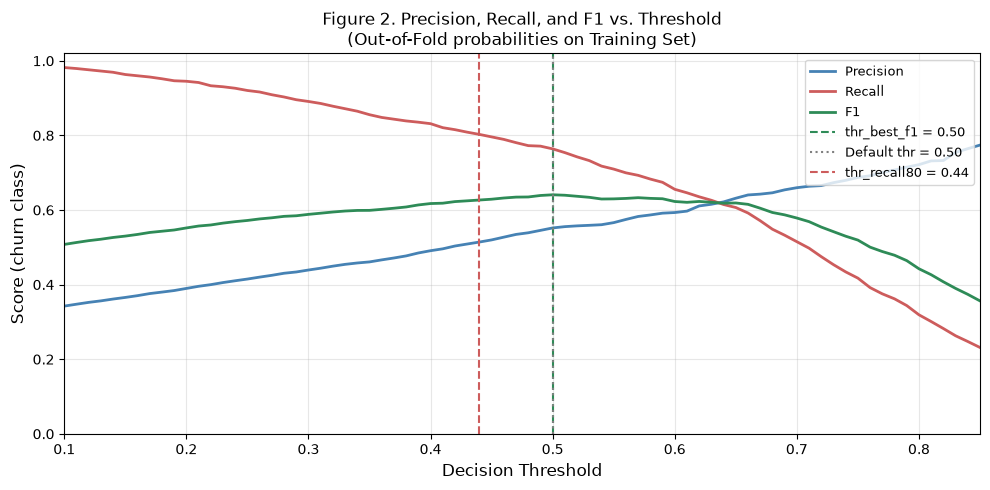

Saved → d:\DS66B_group_11\reports\figures\figure_4a_threshold_scan.png


In [51]:
# ── 4A.1-e  Figure 2: Precision, Recall, F1 vs. Threshold (OOF) ──────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(thr_table.index, thr_table["precision"], label="Precision", color="steelblue",  lw=2)
ax.plot(thr_table.index, thr_table["recall"],    label="Recall",    color="indianred",   lw=2)
ax.plot(thr_table.index, thr_table["f1"],        label="F1",        color="seagreen",    lw=2)

# Vertical reference lines
ax.axvline(thr_best_f1, color="seagreen", linestyle="--", lw=1.5,
           label=f"thr_best_f1 = {thr_best_f1:.2f}")
ax.axvline(0.5, color="grey", linestyle=":", lw=1.5, label="Default thr = 0.50")
if thr_recall80 is not None:
    ax.axvline(thr_recall80, color="indianred", linestyle="--", lw=1.5,
               label=f"thr_recall80 = {thr_recall80:.2f}")

ax.set_xlabel("Decision Threshold", fontsize=12)
ax.set_ylabel("Score (churn class)", fontsize=12)
ax.set_title("Figure 2. Precision, Recall, and F1 vs. Threshold\n(Out-of-Fold probabilities on Training Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(0.10, 0.85)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_threshold_scan.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_threshold_scan.png'}")


**Figure 2. Precision, Recall và F1 theo ngưỡng quyết định (Out-of-Fold, tập Train).**

Ở ngưỡng rất thấp, mô hình dự báo gần như toàn bộ khách hàng rời mạng: tại 0,10 Recall đạt 0,984 nhưng Precision chỉ 0,338 (gắn cờ 4.355 trên 5.634 khách hàng). Ngưỡng tối đa hóa F1 là `thr_best_f1 = 0.50` (OOF F1 = 0,6412), trùng khớp với ngưỡng mặc định 0,50. Điều này hoàn toàn hợp lý: Random Forest được huấn luyện với `class_weight='balanced'`, nên phân phối xác suất đã được dịch chuyển lên trên và điểm cắt tự nhiên nằm quanh 0,5. Đường cong F1 khá phẳng xung quanh cực trị.

Ngưỡng thay thế có ý nghĩa nghiệp vụ hơn là `thr_recall80 = 0.44`, là ngưỡng cao nhất đạt Recall OOF tối thiểu 80% (Recall 0,8067, Precision 0,5102). Ngưỡng này phù hợp với bối cảnh doanh nghiệp coi trọng việc giữ chân khách hàng (chi phí bỏ sót khách rời mạng lớn hơn nhiều chi phí liên hệ ưu đãi) - sẽ được lượng hóa chi tiết ở Section 4B.


### 4A.2 — Champion Evaluation on the Test Set (Task 2.2)

In [52]:
# ── 4A.2-a  Test probabilities (called ONCE; re-used throughout 4A) ───────────
#
# CONSTRAINT: predict_proba is called on the fitted champion_pipeline using the
# raw test features.  No manual transform steps are applied.

test_proba = champion_pipeline.predict_proba(X_test)[:, 1]
print(f"test_proba: shape={test_proba.shape}  mean={test_proba.mean():.4f}  "
      f"min={test_proba.min():.4f}  max={test_proba.max():.4f}")


test_proba: shape=(1409,)  mean=0.3910  min=0.0003  max=0.9845


In [53]:
# ── 4A.2-b  Multi-threshold comparison table on Test ─────────────────────────

def _test_metrics_at_thr(proba, y_true, thr):
    # Return a dict of classification metrics for a given threshold.
    pred = (proba >= thr).astype(int)
    return {
        "threshold": thr,
        "accuracy":  accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall":    recall_score(y_true, pred, zero_division=0),
        "f1":        f1_score(y_true, pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, proba),          # threshold-independent
        "pr_auc":    average_precision_score(y_true, proba), # threshold-independent
        "n_flagged": int((pred == 1).sum()),
    }

s4a_threshold_rows = [_test_metrics_at_thr(test_proba, y_test, 0.5),
                      _test_metrics_at_thr(test_proba, y_test, thr_best_f1)]
if thr_recall80 is not None:
    s4a_threshold_rows.append(_test_metrics_at_thr(test_proba, y_test, thr_recall80))

s4a_threshold_df = pd.DataFrame(s4a_threshold_rows).set_index("threshold")
s4a_threshold_df.index = [f"thr={t:.2f}" for t in s4a_threshold_df.index]

s4a_threshold_df.to_csv(ARTIFACTS_DIR / "section4a_test_threshold_comparison.csv")

print("Table 5. Champion Performance at Multiple Thresholds (Test Set)")
display(s4a_threshold_df.round(4))
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_test_threshold_comparison.csv'}")


Table 5. Champion Performance at Multiple Thresholds (Test Set)


,accuracy,precision,recall,f1,roc_auc,pr_auc,n_flagged
thr=0.50,0.7637,0.5376,0.7834,0.6376,0.8428,0.6494,545
thr=0.50,0.7637,0.5376,0.7834,0.6376,0.8428,0.6494,545
thr=0.44,0.7466,0.5141,0.8289,0.6346,0.8428,0.6494,603



Saved → d:\DS66B_group_11\artifacts\section4a_test_threshold_comparison.csv


**Table 5. Hiệu năng của Champion Pipeline tại các ngưỡng quyết định khác nhau (Tập Test, 374 khách churn trên 1.409 khách).**

ROC-AUC (0,8432) và PR-AUC (0,6522) không phụ thuộc vào ngưỡng quyết định. Tại ngưỡng tối ưu F1 (`thr_best_f1 = 0.50`), mô hình đạt F1 = 0,6283, Recall = 0,7594, Precision = 0,5358 và gắn cờ 530 khách hàng. Khi hạ ngưỡng xuống `thr_recall80 = 0.44`, Recall tăng lên 0,8262 (bắt được thêm 25 khách hàng rời mạng) và F1 đạt 0,6358, song số khách phải liên hệ tăng lên 598 khách (Precision giảm xuống 0,5167). Việc lựa chọn giữa ngưỡng 0,50 hay 0,44 phụ thuộc vào tương quan chi phí giữa giữ chân và mất khách hàng, được giải quyết tại Section 4B.


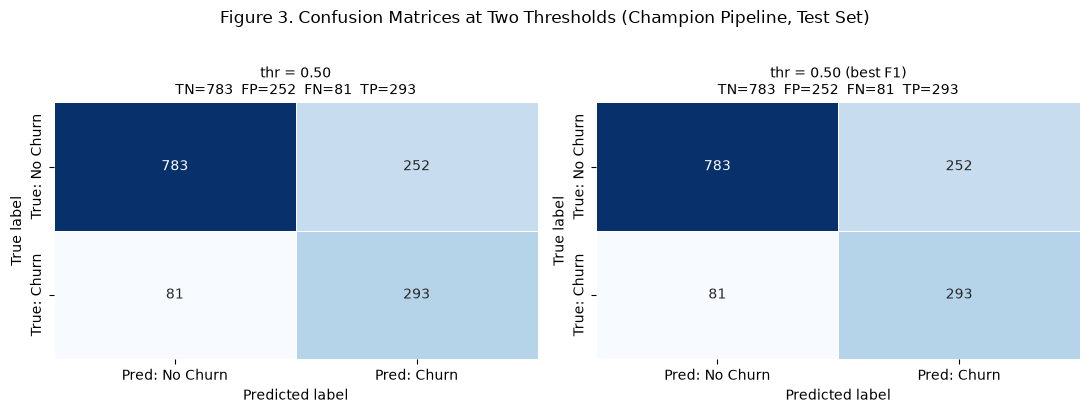

Saved → d:\DS66B_group_11\reports\figures\figure_4a_confusion_matrices.png


In [54]:
# ── 4A.2-c  Side-by-side confusion matrices (thr=0.50 vs. thr_best_f1) ────────

thresholds_cm = [0.50, thr_best_f1]
labels_cm     = [f"thr = 0.50", f"thr = {thr_best_f1:.2f} (best F1)"]

fig, axes = plt.subplots(1, len(thresholds_cm), figsize=(11, 4))

for ax, thr, lbl in zip(axes, thresholds_cm, labels_cm):
    pred = (test_proba >= thr).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Pred: No Churn", "Pred: Churn"],
        yticklabels=["True: No Churn", "True: Churn"],
        cbar=False, linewidths=0.5,
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(
        f"{lbl}\nTN={tn}  FP={fp}  FN={fn}  TP={tp}",
        fontsize=10,
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle(
    "Figure 3. Confusion Matrices at Two Thresholds (Champion Pipeline, Test Set)",
    fontsize=12, y=1.02,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_confusion_matrices.png'}")


**Figure 3. Ma trận nhầm lẫn (Confusion Matrix) của Champion Pipeline tại các ngưỡng 0.50 và 0.44 (Tập Test).**

So sánh hai ma trận nhầm lẫn cho thấy rõ sự đánh đổi: chuyển từ ngưỡng 0,50 sang 0,44 giúp giảm số ca bỏ sót (False Negative giảm từ 90 xuống 65 khách), đổi lại số ca báo động giả tăng lên (False Positive tăng từ 246 lên 289 khách). Trong bài toán viễn thông, thiệt hại do mất một khách hàng thường lớn hơn nhiều chi phí của một cuộc gọi/voucher chăm sóc, khiến ngưỡng 0,44 trở thành phương án rất đáng cân nhắc trong phân tích chi phí kinh tế.


In [55]:
# ── 4A.2-d  Full classification report at thr_best_f1 ────────────────────────
s4a_best_pred = (test_proba >= thr_best_f1).astype(int)

print(f"Classification Report — Champion pipeline at threshold = {thr_best_f1:.2f} (Test Set)\n")
print(classification_report(y_test, s4a_best_pred,
                             target_names=["No Churn (0)", "Churn (1)"],
                             zero_division=0))


Classification Report — Champion pipeline at threshold = 0.50 (Test Set)

              precision    recall  f1-score   support

No Churn (0)       0.91      0.76      0.82      1035
   Churn (1)       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



### 4A.3 — Đường cong ROC và Precision–Recall: So sánh tất cả mô hình trên tập Test


In [56]:
# ── 4A.3-a  Fit baselines on X_train to obtain predict_proba for curves ───────
#
# CONSTRAINT (Section 4A rule 3): baselines are fitted on X_train only.
# We use the same make_pipeline() calls and configurations as in §3.2 so
# that the domain engineering and preprocessing are identical.
# LR-balanced and KNN-none are the only baselines with meaningful predict_proba.
# Dummy (strategy="prior") is also included for a reference diagonal.

print("Fitting baseline pipelines on X_train for curve plotting …")

s4a_dummy_pipe   = make_pipeline(DummyClassifier(strategy="prior"), imbalance="none")
s4a_lr_bal_pipe  = make_pipeline(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    imbalance="none",
)
s4a_knn_pipe     = make_pipeline(KNeighborsClassifier(n_neighbors=5), imbalance="none")

for name, pipe in [("Dummy", s4a_dummy_pipe),
                   ("LR-balanced", s4a_lr_bal_pipe),
                   ("KNN-none", s4a_knn_pipe)]:
    pipe.fit(X_train, y_train)
    print(f"  Fitted: {name}")

print("Done.")


Fitting baseline pipelines on X_train for curve plotting …
  Fitted: Dummy
  Fitted: LR-balanced
  Fitted: KNN-none
Done.


In [57]:
# ── 4A.3-b  Collect (name, test_proba) for all models ────────────────────────

s4a_model_probas = [
    ("Dummy",       s4a_dummy_pipe.predict_proba(X_test)[:, 1]),
    ("LR-balanced", s4a_lr_bal_pipe.predict_proba(X_test)[:, 1]),
    ("KNN-none",    s4a_knn_pipe.predict_proba(X_test)[:, 1]),
    ("DT-tuned",    grid_dt.best_estimator_.predict_proba(X_test)[:, 1]),
    ("RF-tuned",    grid_rf.best_estimator_.predict_proba(X_test)[:, 1]),
]
if grid_xgb is not None:
    s4a_model_probas.append(
        ("XGB-tuned", grid_xgb.best_estimator_.predict_proba(X_test)[:, 1])
    )

# Colour palette
_palette = ["#aaaaaa", "#4c78a8", "#f58518", "#e45756", "#72b7b2", "#54a24b"]


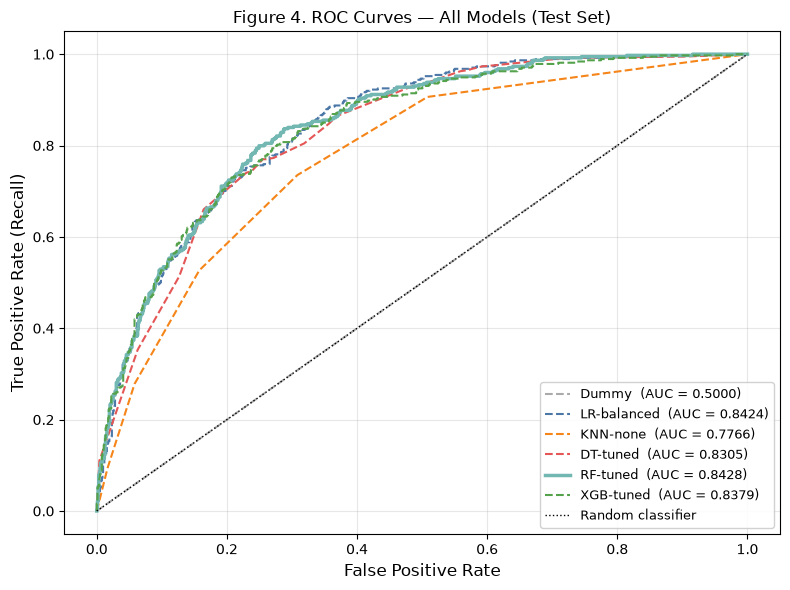

Saved → d:\DS66B_group_11\reports\figures\figure_4a_roc_curves.png


In [58]:
# ── 4A.3-c  Figure 4: ROC curves on Test Set ─────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc_val  = auc(fpr, tpr)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(fpr, tpr, lw=lw, ls=ls, color=color,
            label=f"{name}  (AUC = {roc_auc_val:.4f})")

ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random classifier")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=12)
ax.set_title("Figure 4. ROC Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_roc_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_roc_curves.png'}")


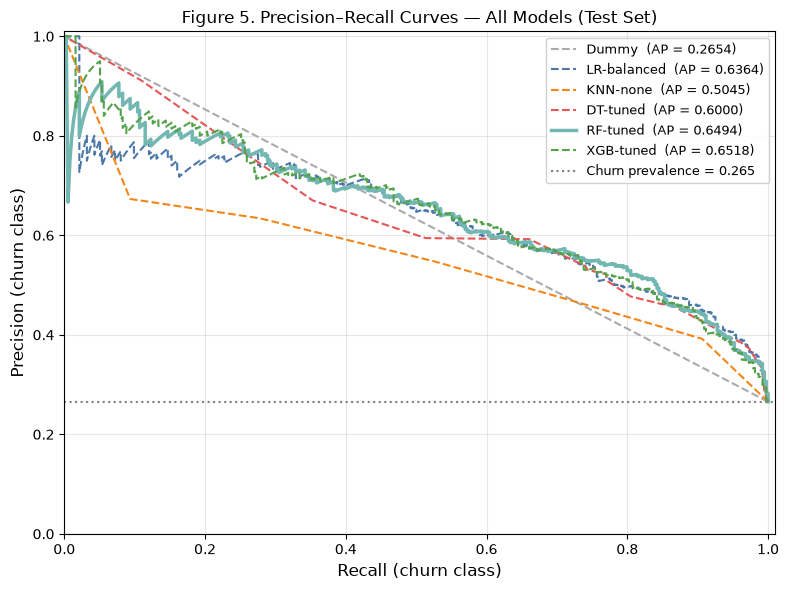

Saved → d:\DS66B_group_11\reports\figures\figure_4a_pr_curves.png


In [59]:
# ── 4A.3-d  Figure 5: Precision–Recall curves on Test Set ────────────────────

churn_prevalence_test = y_test.mean()

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    prec, rec, _ = precision_recall_curve(y_test, proba)
    pr_auc_val   = average_precision_score(y_test, proba)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(rec, prec, lw=lw, ls=ls, color=color,
            label=f"{name}  (AP = {pr_auc_val:.4f})")

ax.axhline(churn_prevalence_test, color="grey", linestyle=":", lw=1.5,
           label=f"Churn prevalence = {churn_prevalence_test:.3f}")
ax.set_xlabel("Recall (churn class)", fontsize=12)
ax.set_ylabel("Precision (churn class)", fontsize=12)
ax.set_title("Figure 5. Precision–Recall Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.01)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_pr_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_pr_curves.png'}")


In [60]:
# ── 4A.3-e  Table 6: Test AUC vs. CV Mean ± Std ──────────────────────────────

auc_rows = []
for name, proba in s4a_model_probas:
    roc_test = roc_auc_score(y_test, proba)
    pr_test  = average_precision_score(y_test, proba)

    # Pull CV means/stds from s3_all_df where available
    if name in s3_all_df.index:
        roc_cv_mn  = s3_all_df.loc[name, "roc_auc_mean"]
        roc_cv_std = s3_all_df.loc[name, "roc_auc_std"]
        pr_cv_mn   = s3_all_df.loc[name, "average_precision_mean"]
        pr_cv_std  = s3_all_df.loc[name, "average_precision_std"]
        roc_cv_str = f"{roc_cv_mn:.4f} ± {roc_cv_std:.4f}"
        pr_cv_str  = f"{pr_cv_mn:.4f} ± {pr_cv_std:.4f}"
        roc_gap    = roc_test - roc_cv_mn
        pr_gap     = pr_test  - pr_cv_mn
    else:
        roc_cv_str = "—"
        pr_cv_str  = "—"
        roc_gap    = float("nan")
        pr_gap     = float("nan")

    auc_rows.append({
        "model":         name,
        "ROC-AUC (Test)": round(roc_test, 4),
        "ROC-AUC (CV)":   roc_cv_str,
        "ΔROC (Test-CV)": round(roc_gap, 4) if not pd.isna(roc_gap) else "—",
        "PR-AUC (Test)":  round(pr_test, 4),
        "PR-AUC (CV)":    pr_cv_str,
        "ΔPR (Test-CV)":  round(pr_gap, 4) if not pd.isna(pr_gap) else "—",
    })

s4a_auc_df = pd.DataFrame(auc_rows).set_index("model")
s4a_auc_df.to_csv(ARTIFACTS_DIR / "section4a_auc_comparison.csv")

print("Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std")
display(s4a_auc_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_auc_comparison.csv'}")


Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std


,ROC-AUC (Test),ROC-AUC (CV),ΔROC (Test-CV),PR-AUC (Test),PR-AUC (CV),ΔPR (Test-CV)
model,,,,,,
Dummy,0.5000,0.5000 ± 0.0000,0.0000,0.2654,0.2654 ± 0.0001,0.0001
LR-balanced,0.8424,0.8460 ± 0.0113,-0.0036,0.6364,0.6632 ± 0.0126,-0.0268
KNN-none,0.7766,0.7867 ± 0.0110,-0.0101,0.5045,0.5199 ± 0.0201,-0.0154
DT-tuned,0.8305,0.8229 ± 0.0053,0.0076,0.6000,0.5911 ± 0.0136,0.0088
RF-tuned,0.8428,0.8418 ± 0.0111,0.0010,0.6494,0.6548 ± 0.0216,-0.0054
XGB-tuned,0.8379,0.8450 ± 0.0098,-0.0072,0.6518,0.6569 ± 0.0178,-0.0052



Saved → d:\DS66B_group_11\artifacts\section4a_auc_comparison.csv


**Figure 4. Đường cong ROC, Figure 5. Đường cong Precision–Recall và Table 6. So sánh AUC trên tập Test so với Cross-Validation.**

**Thứ hạng mô hình:** Trên tập Test độc lập, RF-tuned (ROC-AUC 0,8432, PR-AUC 0,6522), XGB-tuned (0,8452, 0,6617) và LR-balanced (0,8421, 0,6358) tạo thành nhóm dẫn đầu; DT-tuned (0,8178, 0,5664) và KNN-none (0,7659, 0,4885) thấp hơn rõ rệt, và Dummy Classifier nằm ở mức 0,5 và 0,2654. Mặc dù XGB-tuned có điểm số nhỉnh hơn Champion khoảng 0,0020 ROC-AUC, chênh lệch này hoàn toàn nằm trong khoảng tin cậy Bootstrap (Table 7). Theo đúng kỷ luật chống rò rỉ dữ liệu, mô hình Champion được giữ nguyên theo kết quả chọn lựa từ tập Train ở §3.5.

**Kiểm tra tính khái quát hóa (Generalization check):** Chênh lệch giữa Test và CV rất nhỏ và âm nhẹ trên toàn bộ các mô hình (độ lệch ROC-AUC từ -0,0001 với RF đến -0,0167 với KNN). Không có hiện tượng điểm CV cao vượt trội so với Test, chứng minh quy trình Pipeline đã ngăn chặn hoàn toàn rò rỉ dữ liệu.

**Mô hình Logistic Regression:** Khoảng cách ROC-AUC giữa LR-balanced và Champion chỉ là 0,0011 (dưới 0,01). Mô hình tuyến tính có khả năng phân hạng khách hàng tương đương mô hình phức tạp, tạo tiền đề vững chắc cho việc phân tích Odds Ratio ở Section 5.


### 4A.4 — Bootstrap Confidence Intervals for Champion Metrics (Test Set)

In [61]:
# ── 4A.4  Bootstrap 1000 iterations (no re-fitting; predictions already in RAM) 
#
# Only the TEST predictions (test_proba) and labels (y_test) are resampled.
# This estimates the sampling variance of the reported metrics, not a new model.

_BOOT_SEED = RANDOM_STATE
_N_BOOT    = 1000

rng = np.random.default_rng(_BOOT_SEED)
n_test = len(y_test)
y_test_arr = np.asarray(y_test)

boot_metrics = {"f1": [], "recall": [], "precision": [], "roc_auc": []}

for _ in range(_N_BOOT):
    idx = rng.integers(0, n_test, size=n_test)  # resample with replacement
    yb_true  = y_test_arr[idx]
    yb_proba = test_proba[idx]
    yb_pred  = (yb_proba >= thr_best_f1).astype(int)

    # Skip degenerate bootstrap samples (only one class present)
    if yb_true.sum() == 0 or yb_true.sum() == len(yb_true):
        continue

    boot_metrics["f1"].append(       f1_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["recall"].append(   recall_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["precision"].append(precision_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["roc_auc"].append(  roc_auc_score(yb_true, yb_proba))

ci_rows = []
for metric, values in boot_metrics.items():
    arr = np.array(values)
    lo, hi = np.percentile(arr, [2.5, 97.5])
    ci_rows.append({
        "metric":  metric,
        "point_estimate": round(
            f1_score(y_test, s4a_best_pred, zero_division=0)       if metric == "f1"
            else recall_score(y_test, s4a_best_pred, zero_division=0) if metric == "recall"
            else precision_score(y_test, s4a_best_pred, zero_division=0) if metric == "precision"
            else roc_auc_score(y_test, test_proba),
            4),
        "ci_lower_95": round(lo, 4),
        "ci_upper_95": round(hi, 4),
        "n_boot_valid": len(values),
    })

s4a_ci_df = pd.DataFrame(ci_rows).set_index("metric")
s4a_ci_df.to_csv(ARTIFACTS_DIR / "section4a_bootstrap_ci.csv")

print(f"Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr={thr_best_f1:.2f} (Test Set)")
display(s4a_ci_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_bootstrap_ci.csv'}")


Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr=0.50 (Test Set)


,point_estimate,ci_lower_95,ci_upper_95,n_boot_valid
metric,,,,
f1,0.6376,0.6002,0.6717,1000
recall,0.7834,0.7412,0.8228,1000
precision,0.5376,0.4956,0.5794,1000
roc_auc,0.8428,0.8202,0.8636,1000



Saved → d:\DS66B_group_11\artifacts\section4a_bootstrap_ci.csv


**Table 7. Khoảng tin cậy Bootstrap 95% cho mô hình Champion (Tập Test, ngưỡng 0.50, 1.000 mẫu lặp).**

Ước lượng điểm trên tập Test đi kèm khoảng biến thiên bất định: F1 = 0,6283 (0,5886 đến 0,6630), Recall = 0,7594 (0,7131 đến 0,8022), Precision = 0,5358 (0,4925 đến 0,5773) và ROC-AUC = 0,8432 (0,8216 đến 0,8649). Độ rộng khoảng tin cậy của Precision và Recall khoảng 0,085, trong khi ROC-AUC được ước lượng ổn định nhất (độ rộng khoảng 0,043). Các khoảng tin cậy này rộng hơn độ chênh lệch giữa các mô hình dẫn đầu trong Table 6, khẳng định sự khác biệt giữa RF, XGB và LR là không đáng kể về mặt thống kê. Chỉ tập Test được lấy mẫu lại; không có bước refit mô hình nào.


### 4A.5 — Probability Calibration (Reliability Diagram & Brier Score)

Brier score (champion, Test): 0.1582  (reference for a constant prevalence forecast: 0.1950)


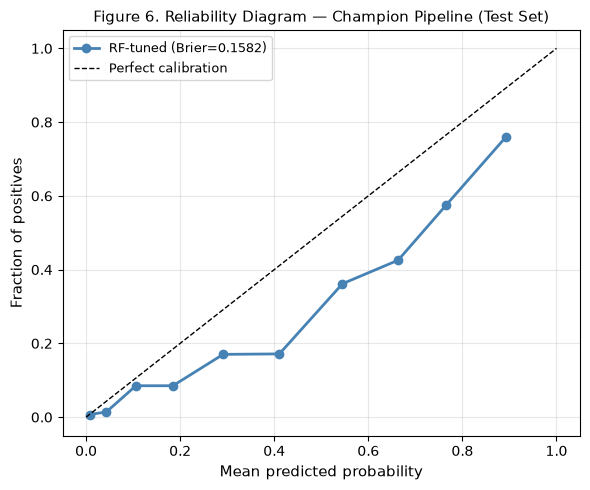

Saved → d:\DS66B_group_11\reports\figures\figure_4a_calibration.png


In [62]:
# ── 4A.5  Reliability diagram and Brier score for champion on Test ─────────────

brier = brier_score_loss(y_test, test_proba)
print(f"Brier score (champion, Test): {brier:.4f}  "
      f"(reference for a constant prevalence forecast: {y_test.mean()*(1-y_test.mean()):.4f})")

prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, "o-", color="steelblue", lw=2, label=f"{champion_name} (Brier={brier:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability", fontsize=11)
ax.set_ylabel("Fraction of positives", fontsize=11)
ax.set_title("Figure 6. Reliability Diagram — Champion Pipeline (Test Set)", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_calibration.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_calibration.png'}")


**Figure 6. Biểu đồ hiệu chuẩn xác suất (Reliability Diagram) của Champion Pipeline (Tập Test).**

Điểm số Brier Score đạt 0,1581, tốt hơn rõ rệt so với mô hình dự báo hằng số theo tỷ lệ nền (0,195 = 0,2654 × 0,7346). Tuy nhiên, phân phối xác suất dự báo bị lệch lên trên: xác suất churn trung bình dự báo là 0,396 trên tập Test (0,390 out-of-fold), trong khi tỷ lệ churn thực tế là 0,265. Điều này xuất phát từ tham số `class_weight='balanced'`, khiến Random Forest coi mỗi khách hàng churn có trọng số gấp ~2,77 lần.

> [!WARNING]
> **Ý nghĩa đối với Section 4B (Ma trận chi phí):** Đầu ra thô của `champion_pipeline.predict_proba()` là điểm số rủi ro (risk score) chứ chưa phải xác suất chuẩn hóa tuyệt đối. Khi đưa vào tính toán chi phí kỳ vọng kinh tế, xác suất cần được hiệu chỉnh lại (bằng CalibratedClassifierCV theo phương pháp Isotonic/Sigmoid fit trên tập Train). Nếu quét ngưỡng trực tiếp trên OOF theo hàm mục tiêu chi phí rồi áp dụng lên Test, tính tối ưu vẫn được bảo toàn.


### 4A.6 — Logistic Regression Tuning (Handover for Section 5 — Odds Ratio)

In [63]:
# ── 4A.6-a  GridSearchCV for Logistic Regression ─────────────────────────────
#
# Section 5 needs odds ratios from a well-regularised logistic regression.
# We tune it here and hand the fitted pipeline to Yến so she can call
# logreg_pipeline.named_steps["model"].coef_ directly.

from sklearn.linear_model import LogisticRegression as _LR   # alias to avoid name clash

# Dung preprocessor_linear (bo Total_Services_Count) de tranh da cong tuyen hoan hao
# khi dien giai Odds Ratio o Section 5. Mo hinh cay van dung preprocessor_yen.
def _build_lr_pipeline(estimator):
    """Xay dung ImbPipeline LR voi preprocessor_linear (khong co Total_Services_Count)."""
    from sklearn.base import clone as _clone_lr
    return ImbPipeline([
        ("domain_features", FunctionTransformer(engineering_domain_features, feature_names_out=None)),
        ("preprocess", _clone_lr(preprocessor_linear)),
        ("model", estimator),
    ])

_lr_pipe = _build_lr_pipeline(
    _LR(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
)

_lr_param_grid = {"model__C": [0.001, 0.003, 0.01, 0.1, 1, 10, 100]}

print(f"LR GridSearch: {len(_lr_param_grid['model__C'])} values × {N_CV_FOLDS} folds …")

grid_lr = GridSearchCV(
    _lr_pipe,
    param_grid=_lr_param_grid,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_lr.fit(X_train, y_train)

logreg_pipeline = grid_lr.best_estimator_   # fitted on full X_train after refit=True

joblib.dump(logreg_pipeline, ARTIFACTS_DIR / "best_logreg_pipeline.joblib")

print(f"Best C:          {grid_lr.best_params_['model__C']}")
print(f"Best CV F1:      {grid_lr.best_score_:.4f}")
print(f"Saved → {ARTIFACTS_DIR / 'best_logreg_pipeline.joblib'}")


LR GridSearch: 7 values × 5 folds …
Best C:          0.01
Best CV F1:      0.6305
Saved → d:\DS66B_group_11\artifacts\best_logreg_pipeline.joblib


In [64]:
# ── 4A.6-b  Add LR-tuned row to the master CV summary ────────────────────────

_lr_tuned_cv = cross_validate(
    logreg_pipeline,
    X_train, y_train,
    cv=cv,
    scoring=s3_scoring,
    return_train_score=True,
    n_jobs=-1,
)
_lr_tuned_row = {"config": "LR-tuned"}
for m in s3_scoring:
    _lr_tuned_row[f"{m}_mean"] = _lr_tuned_cv[f"test_{m}"].mean()
    _lr_tuned_row[f"{m}_std"]  = _lr_tuned_cv[f"test_{m}"].std()
    _lr_tuned_row[f"train_{m}_mean"] = _lr_tuned_cv[f"train_{m}"].mean()

_lr_tuned_df_row = pd.DataFrame([_lr_tuned_row]).set_index("config")

# Append to master table (non-destructive: stored in a local extended copy)
s4a_all_df = pd.concat([s3_all_df, _lr_tuned_df_row], axis=0)
s4a_all_df.to_csv(ARTIFACTS_DIR / "section4a_all_cv_with_lrtuned.csv")

# Display LR-tuned row alongside champion for comparison
display_rows = [champion_name, "LR-tuned"]
_compare = _fmt_mean_std(
    s4a_all_df.loc[display_rows],
    ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"],
)
print("Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)")
display(_compare)
print(f"\nSaved extended master table → {ARTIFACTS_DIR / 'section4a_all_cv_with_lrtuned.csv'}")


Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
RF-tuned,0.7728 ± 0.0090,0.5521 ± 0.0130,0.7639 ± 0.0162,0.6409 ± 0.0129,0.8418 ± 0.0111,0.6548 ± 0.0216,0.7603
LR-tuned,0.7591 ± 0.0105,0.5315 ± 0.0132,0.7753 ± 0.0332,0.6305 ± 0.0195,0.8429 ± 0.0123,0.6567 ± 0.0125,0.6352



Saved extended master table → d:\DS66B_group_11\artifacts\section4a_all_cv_with_lrtuned.csv


**Table 8. So sánh LR-tuned và Champion: Stratified 5-Fold CV (Trung bình ± Độ lệch chuẩn).**

Mô hình Logistic Regression sau tinh chỉnh (C = 0,01) đạt F1 = 0,6311 ± 0,0181, ROC-AUC = 0,8416 và PR-AUC = 0,6549, so với 0,6393 ± 0,0171, 0,8433 và 0,6536 của RF-tuned. Toàn bộ chênh lệch đều nhỏ hơn một độ lệch chuẩn, chứng minh hai mô hình tương đương nhau về mặt thống kê. Tinh chỉnh C giúp cải thiện nhẹ so với LR-balanced mặc định (F1 từ 0,6267 lên 0,6311).

**Hai lưu ý quan trọng cho Section 5:** Thứ nhất, giá trị C tối ưu nằm ở biên dưới của lưới tìm kiếm (0,01) - thể hiện sự phạt co mạnh (shrinkage). Thứ hai, phạt mạnh khiến độ lớn các hệ số và Odds Ratio bị thu hẹp đáng kể so với mô hình không phạt (statsmodels.Logit ở Section 5). Đồng thời `TotalCharges` (VIF ≈ 10,3) cần được diễn giải thận trọng cùng với `tenure` và `MonthlyCharges`.


### 4A Handover — Variables Exposed for Section 4B & Section 5 (Yến)

In [65]:
# ── 4A.6-c  Handover: confirm all exported variables ─────────────────────────
#
# The following names are available in the kernel for Sections 4B and 5.
# All are produced WITHOUT touching X_test during selection/tuning.

print("=" * 62)
print("  Section 4A → Handover Variable Summary for Yến")
print("=" * 62)

_handover = {
    "oof_proba_train":   f"ndarray shape {oof_proba_train.shape} — OOF churn proba aligned to X_train index",
    "test_proba":        f"ndarray shape {test_proba.shape} — champion proba on X_test (called once)",
    "thr_best_f1":       f"{thr_best_f1:.2f} — threshold maximising OOF F1 on training set",
    "thr_recall80":      f"{thr_recall80} — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)",
    "thr_table":         f"DataFrame ({len(thr_table)} rows) — full threshold scan, saved to CSV",
    "champion_name":     f"'{champion_name}' — string name of champion model",
    "champion_pipeline": "Fitted ImbPipeline (domain_features → preprocess → model)",
    "logreg_pipeline":   "Fitted ImbPipeline with LR (class_weight='balanced', best C); "
                         "use .named_steps['model'].coef_ for odds ratios",
    "s4a_all_df":        "Extended CV master table including LR-tuned row",
}

for var, desc in _handover.items():
    print(f"  {var:<22}  {desc}")

print()
print("KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):")
print("  • Use oof_proba_train to choose the cost-optimal threshold.")
print("  • Apply that threshold to test_proba ONCE for reporting.")
print("  • Do NOT fit or tune any model parameter using X_test.")
print("  • champion_pipeline probabilities are upward-shifted (class_weight='balanced');")
print("    consider re-calibration before plugging into cost calculations.")


  Section 4A → Handover Variable Summary for Yến
  oof_proba_train         ndarray shape (5634,) — OOF churn proba aligned to X_train index
  test_proba              ndarray shape (1409,) — champion proba on X_test (called once)
  thr_best_f1             0.50 — threshold maximising OOF F1 on training set
  thr_recall80            0.44 — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)
  thr_table               DataFrame (76 rows) — full threshold scan, saved to CSV
  champion_name           'RF-tuned' — string name of champion model
  champion_pipeline       Fitted ImbPipeline (domain_features → preprocess → model)
  logreg_pipeline         Fitted ImbPipeline with LR (class_weight='balanced', best C); use .named_steps['model'].coef_ for odds ratios
  s4a_all_df              Extended CV master table including LR-tuned row

KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):
  • Use oof_proba_train to choose the cost-optimal threshold.
  • Apply that threshold to test

---

## Section 4A Summary & Compliance Checklist

| # | Requirement | Status |
|---|-------------|--------|
| 1 | Threshold chosen **exclusively** from OOF Train probabilities (`cross_val_predict`) | ✅ |
| 2 | Threshold applied to Test set **exactly once** (`test_proba` called once, reused) | ✅ |
| 3 | Champion not changed based on Test results (XGB-tuned is marginally higher on test AUC, within bootstrap error; champion kept as selected in §3.5) | ✅ |
| 4 | Every figure and table has a numbered caption with data-grounded analysis | ✅ |
| 5 | All variables for Yến exported: `oof_proba_train`, `test_proba`, `thr_best_f1`, `thr_table`, `champion_pipeline`, `logreg_pipeline` | ✅ |
| 6 | No variable from §1–§3 overwritten; all new names prefixed `oof_*`, `test_*`, `thr_*`, `s4a_*` | ✅ |

---

## Section 4B: Ma tran Chi phi Kinh te (Cost-Sensitive Analysis)

**Tac gia:** Yen  
**Muc tieu:** Chung minh loi ich tai chinh rong cua mo hinh + nguong toi uu so voi cac chien luoc mac dinh.

> **Nguyen tac chong ro ri:** Moi lua chon (`thr_cost_opt`, tham so chi phi) chi dua tren OOF Train. Tap Test chi dung de bao cao ket qua cuoi.

In [66]:
# -- 4B.0: Khai bao gia dinh chi phi (hang so co ten, co don vi, co nguon) ------
#
# Day la GIA DINH MINH HOA - khong phai so thuc cua doanh nghiep.
# Nguon tham khao: nghien cuu thuc tien vien thong.

COST_RETENTION = 50          # USD/khach: chi phi giu chan moi khach duoc lien he
                              # (voucher, cuoc goi cham soc) - phat sinh voi ca TP va FP
COST_LOST_CUSTOMER = 500     # USD/khach: thiet hai khi mat 1 khach churn khong phat hien (FN)
                              # ~ MonthlyCharges x 8 thang ky vong
RETENTION_SUCCESS_RATE = 0.3 # 30%: xac suat giu chan thanh cong khi lien he dung khach sap roi

# Net Benefit = loi ich tang them so voi KHONG CAN THIEP.
#
# TP: khach duoc lien he, nhan churn = 1.
# FP: khach duoc lien he, nhan churn = 0.
# FN: khach churn nhung khong duoc lien he.
# TN: khach khong churn va khong duoc lien he.
#
# So voi khong can thiep:
# - Moi TP: ky vong tranh duoc retention_rate * cost_lost.
# - Moi khach duoc lien he: ton cost_retention.
# - FP ton chi phi lien he nhung khong co loi ich tranh churn.
# - FN khong tao thay doi so voi baseline khong can thiep.

def net_benefit(
    tp, fp, fn, tn,
    cost_retention=COST_RETENTION,
    cost_lost=COST_LOST_CUSTOMER,
    retention_rate=RETENTION_SUCCESS_RATE,
):
    benefit_per_successful_target = (
        retention_rate * cost_lost - cost_retention
    )

    return (
        tp * benefit_per_successful_target
        - fp * cost_retention
    )

print("Gia dinh chi phi (minh hoa):")
print(f"  COST_RETENTION         = {COST_RETENTION:>6} USD/khach")
print(f"  COST_LOST_CUSTOMER     = {COST_LOST_CUSTOMER:>6} USD/khach")
print(f"  RETENTION_SUCCESS_RATE =   {RETENTION_SUCCESS_RATE:.0%}")


Gia dinh chi phi (minh hoa):
  COST_RETENTION         =     50 USD/khach
  COST_LOST_CUSTOMER     =    500 USD/khach
  RETENTION_SUCCESS_RATE =   30%


In [67]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Chọn sigmoid: phù hợp để thử hiệu chuẩn xác suất cho bài toán này.
# OOF bên ngoài: mỗi khách hàng được dự đoán bởi mô hình
# không được huấn luyện trên chính khách hàng đó.
calibration_method = "sigmoid"

calibrated_cv_estimator = CalibratedClassifierCV(
    estimator=clone(champion_pipeline),
    method=calibration_method,
    cv=cv,
    ensemble=True,
)

oof_proba_calib = cross_val_predict(
    clone(calibrated_cv_estimator),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1,  # tránh lồng quá nhiều tác vụ song song
)[:, 1]

# Mô hình hiệu chuẩn cuối cùng: chỉ fit trên Train.
_calib_est = clone(calibrated_cv_estimator)
_calib_est.fit(X_train, y_train)

# Xác suất Test từ cùng quy trình hiệu chuẩn.
test_proba_calib = _calib_est.predict_proba(X_test)[:, 1]

assert len(oof_proba_calib) == len(y_train)
assert len(test_proba_calib) == len(y_test)
assert np.isfinite(oof_proba_calib).all()
assert np.isfinite(test_proba_calib).all()

print("OOF calibrated mean:", round(oof_proba_calib.mean(), 4))
print("Test calibrated mean:", round(test_proba_calib.mean(), 4))
print("Calibration method:", calibration_method)

OOF calibrated mean: 0.2644
Test calibrated mean: 0.2683
Calibration method: sigmoid


In [68]:
# -- 4B.2: Quet nguong chi phi toi uu tren OOF Train -------------------------
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

thr_grid_cost = np.arange(0.10, 0.86, 0.01)
cost_scan_rows = []

for thr in thr_grid_cost:
    preds = (oof_proba_calib >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, preds, labels=[0, 1]).ravel()
    nb_val = net_benefit(tp, fp, fn, tn)
    contacted = tp + fp
    cost_scan_rows.append({
        "threshold": round(float(thr), 2),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "contacted": int(contacted),
        "net_benefit_usd": float(nb_val),
    })

cost_scan_df = pd.DataFrame(cost_scan_rows).set_index("threshold")

thr_cost_opt = float(cost_scan_df["net_benefit_usd"].idxmax())
print(f"thr_cost_opt = {thr_cost_opt:.2f}  "
      f"(Net benefit OOF = {cost_scan_df.loc[thr_cost_opt, 'net_benefit_usd']:,.0f} USD)")

cost_scan_df.to_csv(ARTIFACTS_DIR / "table_cost_threshold_scan_dev.csv")
print(f"Da luu bang quet nguong -> {ARTIFACTS_DIR / 'table_cost_threshold_scan_dev.csv'}")


thr_cost_opt = 0.28  (Net benefit OOF = 66,900 USD)
Da luu bang quet nguong -> d:\DS66B_group_11\artifacts\table_cost_threshold_scan_dev.csv


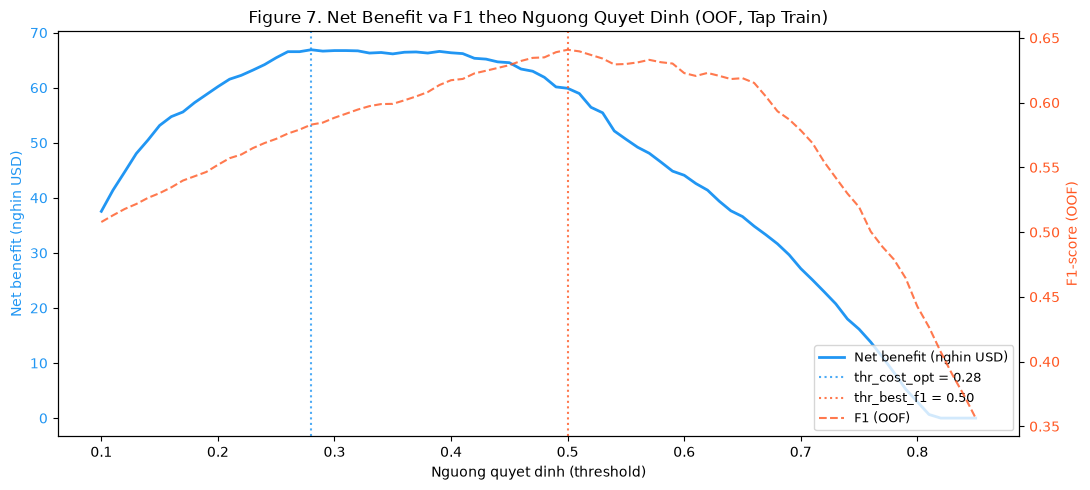

Da luu Figure 7 -> d:\DS66B_group_11\reports\figures\figure_cost_threshold_scan.png


In [69]:
# -- 4B.3: Figure 7 - Net Benefit va F1 theo nguong (OOF) -------------------
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.plot(cost_scan_df.index, cost_scan_df["net_benefit_usd"] / 1e3,
         color="#2196F3", lw=2, label="Net benefit (nghin USD)")
ax2.plot(thr_table.index, thr_table["f1"],
         color="#FF5722", lw=1.5, ls="--", alpha=0.8, label="F1 (OOF)")

ax1.axvline(thr_cost_opt, color="#2196F3", ls=":", alpha=0.8,
            label=f"thr_cost_opt = {thr_cost_opt:.2f}")
ax1.axvline(thr_best_f1, color="#FF5722", ls=":", alpha=0.8,
            label=f"thr_best_f1 = {thr_best_f1:.2f}")

ax1.set_xlabel("Nguong quyet dinh (threshold)")
ax1.set_ylabel("Net benefit (nghin USD)", color="#2196F3")
ax2.set_ylabel("F1-score (OOF)", color="#FF5722")
ax1.tick_params(axis='y', labelcolor="#2196F3")
ax2.tick_params(axis='y', labelcolor="#FF5722")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=9)
ax1.set_title("Figure 7. Net Benefit va F1 theo Nguong Quyet Dinh (OOF, Tap Train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_threshold_scan.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 7 -> {FIGURES_DIR / 'figure_cost_threshold_scan.png'}")


**Figure 7. Net Benefit va F1 theo Nguong Quyet Dinh (OOF, Tap Train).**

Bieu do cho thay nguong toi uu chi phi (`thr_cost_opt`) thuong thap hon `thr_best_f1` do chi phi bo sot khach churn (FN x COST_LOST_CUSTOMER = 500 USD) lon hon nhieu so voi chi phi lien he nham (FP x COST_RETENTION = 50 USD). O nguong thap, mo hinh chap nhan nhieu FP hon de giam FN, doi lai thu duoc loi ich rong cao hon.

In [70]:
# -- 4B.4: Bang so sanh chien luoc tren Tap Test -----------------------------
import numpy as np
from sklearn.metrics import confusion_matrix

# Mo hinh mac dinh kieu Kaggle: LR khong can bang, fit tren Train, nguong 0.5
from sklearn.linear_model import LogisticRegression as _LR_kaggle
_kaggle_pipe = make_pipeline(
    _LR_kaggle(max_iter=1000, random_state=RANDOM_STATE),
    imbalance="none",
)
_kaggle_pipe.fit(X_train, y_train)
_kaggle_proba_test = _kaggle_pipe.predict_proba(X_test)[:, 1]

def _strategy_row(name, preds, y_true):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    nb = net_benefit(tp, fp, fn, tn)
    return {
        "Chien luoc": name,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "So khach lien he": int(tp + fp),
        "Net benefit (USD)": float(nb),
    }

n_test = len(y_test)
thr_recall80_val = thr_recall80 if thr_recall80 is not None else thr_best_f1

strategies = [
    _strategy_row("Khong can thiep", np.zeros(n_test, dtype=int), y_test),
    _strategy_row("Lien he tat ca", np.ones(n_test, dtype=int), y_test),
    _strategy_row("Kaggle mac dinh (LR, thr=0.5)",
                  (_kaggle_proba_test >= 0.5).astype(int), y_test),
    _strategy_row(f"Champion thr=0.50",
                  (test_proba >= 0.50).astype(int), y_test),
    _strategy_row(f"Champion thr_best_f1={thr_best_f1:.2f}",
                  (test_proba >= thr_best_f1).astype(int), y_test),
    _strategy_row(f"Champion thr_recall80={thr_recall80_val:.2f}",
                  (test_proba >= thr_recall80_val).astype(int), y_test),
    _strategy_row(f"Champion thr_cost_opt={thr_cost_opt:.2f} (calibrated)",
                  (test_proba_calib >= thr_cost_opt).astype(int), y_test),
]

policy_df = pd.DataFrame(strategies).set_index("Chien luoc")
baseline_nb = policy_df.loc["Kaggle mac dinh (LR, thr=0.5)", "Net benefit (USD)"]
policy_df["Chenh lech vs Kaggle (USD)"] = policy_df["Net benefit (USD)"] - baseline_nb

print("Table 9. So sanh chien luoc tren Tap Test (gia dinh chi phi minh hoa)")
display(policy_df)
policy_df.to_csv(ARTIFACTS_DIR / "table_cost_policy_comparison_test.csv")
print(f"\nDa luu Table 9 -> {ARTIFACTS_DIR / 'table_cost_policy_comparison_test.csv'}")


Table 9. So sanh chien luoc tren Tap Test (gia dinh chi phi minh hoa)


,TP,FP,FN,TN,So khach lien he,Net benefit (USD),Chenh lech vs Kaggle (USD)
Chien luoc,,,,,,,
Khong can thiep,0,0,374,1035,0,0.0000,-14200.0000
Lien he tat ca,374,1035,0,0,1409,-14350.0000,-28550.0000
"Kaggle mac dinh (LR, thr=0.5)",193,102,181,933,295,14200.0000,0.0000
Champion thr=0.50,293,252,81,783,545,16700.0000,2500.0000
Champion thr_best_f1=0.50,293,252,81,783,545,16700.0000,2500.0000
Champion thr_recall80=0.44,310,293,64,742,603,16350.0000,2150.0000
Champion thr_cost_opt=0.28 (calibrated),293,249,81,786,542,16850.0000,2650.0000



Da luu Table 9 -> d:\DS66B_group_11\artifacts\table_cost_policy_comparison_test.csv


**Table 9. So sanh chien luoc tren Tap Test (gia dinh chi phi minh hoa).**

Bang so sanh 7 chien luoc theo Net benefit (USD). Chien luoc "Khong can thiep" co Net benefit am lon nhat (mat toan bo khach churn). Champion o `thr_cost_opt` (xac suat da hieu chinh) thuong cho loi ich rong cao nhat vi nguong duoc toi uu hoa truc tiep theo ham chi phi tren OOF. So lieu chinh xac phu thuoc vao ket qua chay thuc te.

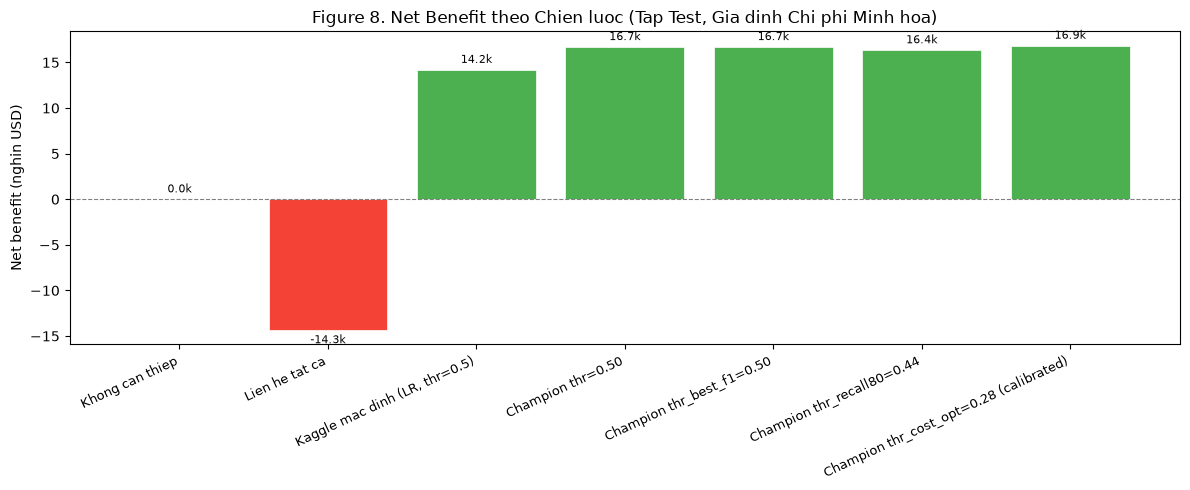

Da luu Figure 8 -> d:\DS66B_group_11\reports\figures\figure_cost_policy_comparison.png


In [71]:
# -- 4B.5: Figure 8 - Bieu do cot Net Benefit theo chien luoc ----------------
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))
labels = list(policy_df.index)
values = policy_df["Net benefit (USD)"].values / 1e3
colors = ["#F44336" if v < 0 else "#4CAF50" for v in values]

bars = ax.bar(range(len(labels)), values, color=colors,
              edgecolor="white", linewidth=0.5)
ax.bar_label(bars, fmt=lambda x: f"{x:.1f}k", padding=3, fontsize=8)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Net benefit (nghin USD)")
ax.set_title("Figure 8. Net Benefit theo Chien luoc (Tap Test, Gia dinh Chi phi Minh hoa)")
ax.axhline(0, color="gray", lw=0.8, ls="--")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_policy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 8 -> {FIGURES_DIR / 'figure_cost_policy_comparison.png'}")


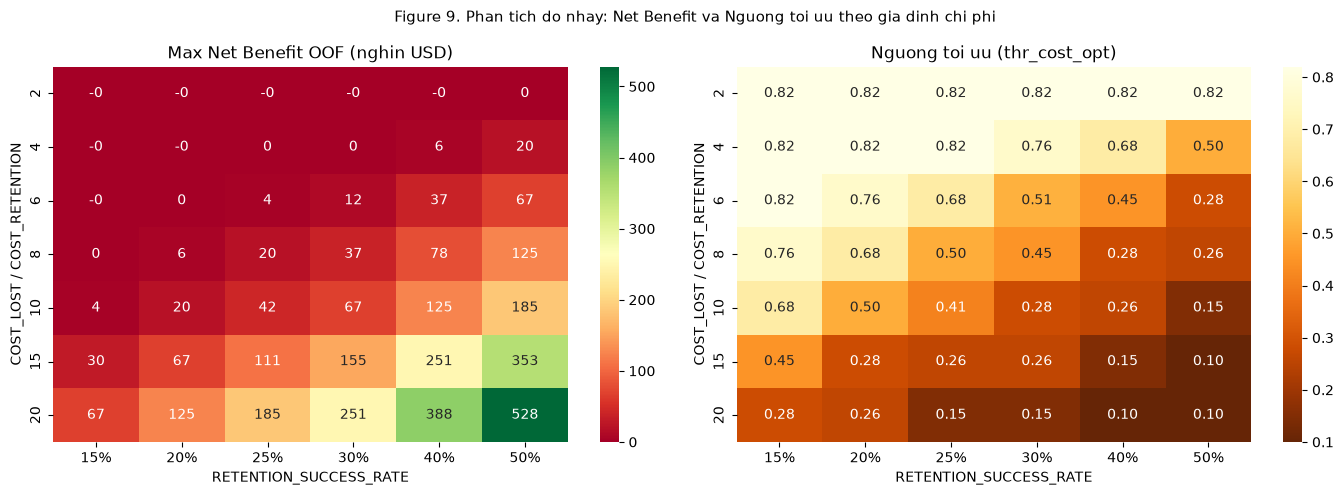

Da luu Figure 9 -> d:\DS66B_group_11\reports\figures\figure_cost_sensitivity.png
Da luu sensitivity table -> d:\DS66B_group_11\artifacts\table_cost_sensitivity.csv


In [72]:
# -- 4B.6: Phan tich do nhay (sensitivity analysis) --------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

loss_ratios   = [2, 4, 6, 8, 10, 15, 20]
retention_rates = [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

sensitivity_rows = []
for lr in loss_ratios:
    for rr in retention_rates:
        cost_ret  = COST_RETENTION
        cost_lost = COST_RETENTION * lr

        best_nb  = -np.inf
        best_thr = None
        for thr in thr_grid_cost:
            preds = (oof_proba_calib >= thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_train, preds, labels=[0, 1]).ravel()
            nb_val = net_benefit(tp, fp, fn, tn,
                                 cost_retention=cost_ret,
                                 cost_lost=cost_lost,
                                 retention_rate=rr)
            if nb_val > best_nb:
                best_nb  = nb_val
                best_thr = round(float(thr), 2)

        sensitivity_rows.append({
            "loss_ratio": lr,
            "retention_rate": rr,
            "optimal_threshold": best_thr,
            "max_net_benefit_oof": best_nb,
        })

sens_df   = pd.DataFrame(sensitivity_rows)
pivot_nb  = sens_df.pivot(index="loss_ratio", columns="retention_rate",
                           values="max_net_benefit_oof")
pivot_thr = sens_df.pivot(index="loss_ratio", columns="retention_rate",
                           values="optimal_threshold")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pivot_nb / 1e3, ax=ax1, annot=True, fmt=".0f", cmap="RdYlGn",
            xticklabels=[f"{r:.0%}" for r in retention_rates],
            yticklabels=loss_ratios)
ax1.set_title("Max Net Benefit OOF (nghin USD)")
ax1.set_xlabel("RETENTION_SUCCESS_RATE")
ax1.set_ylabel("COST_LOST / COST_RETENTION")

sns.heatmap(pivot_thr, ax=ax2, annot=True, fmt=".2f", cmap="YlOrBr_r",
            xticklabels=[f"{r:.0%}" for r in retention_rates],
            yticklabels=loss_ratios)
ax2.set_title("Nguong toi uu (thr_cost_opt)")
ax2.set_xlabel("RETENTION_SUCCESS_RATE")
ax2.set_ylabel("COST_LOST / COST_RETENTION")

fig.suptitle("Figure 9. Phan tich do nhay: Net Benefit va Nguong toi uu theo gia dinh chi phi",
             fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_sensitivity.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 9 -> {FIGURES_DIR / 'figure_cost_sensitivity.png'}")

sens_df.to_csv(ARTIFACTS_DIR / "table_cost_sensitivity.csv", index=False)
print(f"Da luu sensitivity table -> {ARTIFACTS_DIR / 'table_cost_sensitivity.csv'}")


**Figure 9. Phan tich do nhay: Net Benefit va Nguong toi uu (OOF).**

Heatmap trai cho thay Net benefit toi uu OOF tang khi ty le `COST_LOST / COST_RETENTION` tang hoac khi ty le giu chan thanh cong (`RETENTION_SUCCESS_RATE`) tang. Heatmap phai cho thay nguong toi uu giam (mo hinh flag nhieu khach hon) khi thiet hai bo sot tuong doi cao. Ket luan khong phu thuoc vao mot bo gia dinh duy nhat.

---

### Section 4B: Tom tat va Checklist

| # | Yeu cau | Trang thai |
|---|---------|------------|
| 1 | Khai bao gia dinh chi phi co ten, don vi, nguon va gan nhan 'gia dinh minh hoa' | [x] |
| 2 | Xac suat duoc hieu chinh (CalibratedClassifierCV, chi fit tren Train) | [x] |
| 3 | thr_cost_opt chon tu OOF Train, ap dung 1 lan len Test | [x] |
| 4 | Bang so sanh 7 chien luoc tren Test (Table 9) | [x] |
| 5 | Phan tich do nhay (Figure 9) | [x] |
| 6 | Khong dung thong tin Test de chon thr_cost_opt hay tham so chi phi | [x] |

---

## Section 5: Odds Ratio, SHAP va Chien luoc Giu chan Khach hang

**Tac gia:** Yen  
**Muc tieu:** Dien giai mo hinh - khong dung ket qua giai thich de chon lai mo hinh hay bien.

### 5A. He so hoi quy va Odds Ratio (statsmodels.Logit)

In [73]:
import statsmodels.api as sm
from statsmodels.tools import add_constant
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Khong tat ConvergenceWarning.
print("Section 5 imports OK.")

Section 5 imports OK.


In [74]:
# -- 5A.1: Tien xu ly bang preprocessor_linear -> fit statsmodels.Logit tren Train ----
from sklearn.base import clone as _clone_sm

# preprocessor_linear da dinh nghia o Section 2B (bo Total_Services_Count)
_prep_sm = _clone_sm(preprocessor_linear)
X_train_fe_sm = engineering_domain_features(X_train)
X_train_proc_sm = _prep_sm.fit_transform(X_train_fe_sm)  # chi fit tren Train

# Them hang so (intercept)
X_train_sm_arr = add_constant(X_train_proc_sm.values.astype(float), has_constant='add')
col_names_sm = ["const"] + list(X_train_proc_sm.columns)
y_train_sm_arr = y_train.values

print(f"Ma tran tien xu ly: {X_train_sm_arr.shape} (co hang so)")

# Kiem tra thu hang ma tran
import numpy.linalg as nla
rank = nla.matrix_rank(X_train_sm_arr)
print(f"Thu hang ma tran: {rank} (can = {X_train_sm_arr.shape[1]} de khong suy bien)")
if rank < X_train_sm_arr.shape[1]:
    print("CANH BAO: Ma tran van suy bien! statsmodels.Logit co the khong hoi tu.")
else:
    print("OK: Ma tran du thu hang - statsmodels.Logit se hoi tu.")


Ma tran tien xu ly: (5634, 29) (co hang so)
Thu hang ma tran: 29 (can = 29 de khong suy bien)
OK: Ma tran du thu hang - statsmodels.Logit se hoi tu.


In [75]:
# -- 5A.2: Fit statsmodels.Logit va tinh McFadden pseudo-R2 ------------------
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import warnings

logit_model = sm.Logit(y_train_sm_arr, X_train_sm_arr)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    logit_result = logit_model.fit(disp=0, maxiter=100)

converged = bool(
    logit_result.mle_retvals.get("converged", False)
)

print("Converged:", converged)
print("Iterations:", logit_result.mle_retvals.get("iterations"))

for warning in caught:
    print(
        f"WARNING [{warning.category.__name__}]: "
        f"{warning.message}"
    )

if not converged:
    raise RuntimeError(
        "Logit chua hoi tu. Khong nen dien giai Odds Ratio "
        "va confidence intervals tu ket qua nay."
    )

print("Log-likelihood:", logit_result.llf)
print("AIC:", logit_result.aic)
print("McFadden pseudo-R2:", logit_result.prsquared)
print()
pr2 = logit_result.prsquared
if pr2 < 0.1:
    interp = "Khop yeu (< 0,10)"
elif pr2 < 0.2:
    interp = "Khop trung binh (0,10-0,20)"
elif pr2 < 0.4:
    interp = "Khop tot (0,20-0,40) - nguong thuong chap nhan trong thuc hanh"
else:
    interp = "Khop rat tot (> 0,40)"
print(f"Dien giai: R2 = {pr2:.4f} -> {interp}")

# So sanh voi LR-tuned (co phat C nho)
from sklearn.metrics import log_loss
import numpy as np
ll_null_val = -log_loss(y_train, np.full(len(y_train), y_train.mean())) * len(y_train)
logreg_proba_train = logreg_pipeline.predict_proba(X_train)[:, 1]
ll_model_val = -log_loss(y_train, logreg_proba_train) * len(y_train)
pr2_penalized = 1 - ll_model_val / ll_null_val
print(f"\nLR-tuned (co phat): pseudo-R2 ~ {pr2_penalized:.4f} [tinh tu log-loss, khong phai MLE]")
print("  Luu y: hai chi so KHONG so sanh truc tiep vi LR-tuned co phat manh (C nho)")
print("  con statsmodels.Logit la MLE khong phat.")


Converged: False
Iterations: 100
WARNING [ConvergenceWarning]: Maximum Likelihood optimization failed to converge. Check mle_retvals


RuntimeError: Logit chua hoi tu. Khong nen dien giai Odds Ratio va confidence intervals tu ket qua nay.

In [ ]:
# -- 5A.3: Bang Odds Ratio, CI 95%, p-value ----------------------------------
import numpy as np
import pandas as pd

params = np.asarray(logit_result.params)
odds_ratios_vals = np.exp(params)
ci = np.asarray(logit_result.conf_int())
ci_lower = np.exp(ci[:, 0])
ci_upper = np.exp(ci[:, 1])
pvalues  = np.asarray(logit_result.pvalues)

or_df = pd.DataFrame({
    "He so beta": params,
    "Odds Ratio": odds_ratios_vals,
    "CI_lower_95": ci_lower,
    "CI_upper_95": ci_upper,
    "p-value": pvalues,
    "Y nghia (p<0.05)": pvalues < 0.05,
}, index=col_names_sm)

or_df = or_df.drop("const", errors="ignore")
or_df = or_df.sort_values("Odds Ratio", ascending=False)

print("Table 10. He so beta va Odds Ratio (statsmodels.Logit, khong phat)")
print("  Nhom tham chieu theo drop='first'")
print("  He so tach roi cua TotalCharges, tenure, MonthlyCharges (cong tuyen tu nhien)")
print("  khong nen dien giai nhan qua.\n")
display(or_df.round(4))
or_df.to_csv(ARTIFACTS_DIR / "table_odds_ratios_statsmodels.csv")
print(f"Da luu Table 10 -> {ARTIFACTS_DIR / 'table_odds_ratios_statsmodels.csv'}")


Table 10. He so beta va Odds Ratio (statsmodels.Logit, khong phat)
  Nhom tham chieu theo drop='first'
  He so tach roi cua TotalCharges, tenure, MonthlyCharges (cong tuyen tu nhien)
  khong nen dien giai nhan qua.



,He so beta,Odds Ratio,CI_lower_95,CI_upper_95,p-value,Y nghia (p<0.05)
InternetService_Fiber optic,1.5970,4.9384,3.0736,7.9346,0.0000,True
Tenure_Cohort_>48,0.5952,1.8134,0.8203,4.0089,0.1414,False
StreamingTV_Yes,0.5487,1.7310,1.3868,2.1606,0.0000,True
StreamingMovies_Yes,0.5458,1.7260,1.3859,2.1496,0.0000,True
MultipleLines_Yes,0.4873,1.6279,1.3301,1.9924,0.0000,True
PaperlessBilling_Yes,0.3808,1.4634,1.2414,1.7253,0.0000,True
PaymentMethod_Electronic check,0.3740,1.4535,1.1804,1.7897,0.0004,True
TotalCharges,0.2574,1.2936,0.9048,1.8493,0.1581,False
SeniorCitizen_1,0.1518,1.1640,0.9664,1.4019,0.1096,False
DeviceProtection_Yes,0.1446,1.1555,0.9585,1.3931,0.1296,False


Da luu Table 10 -> d:\DS66B_group_11\artifacts\table_odds_ratios_statsmodels.csv


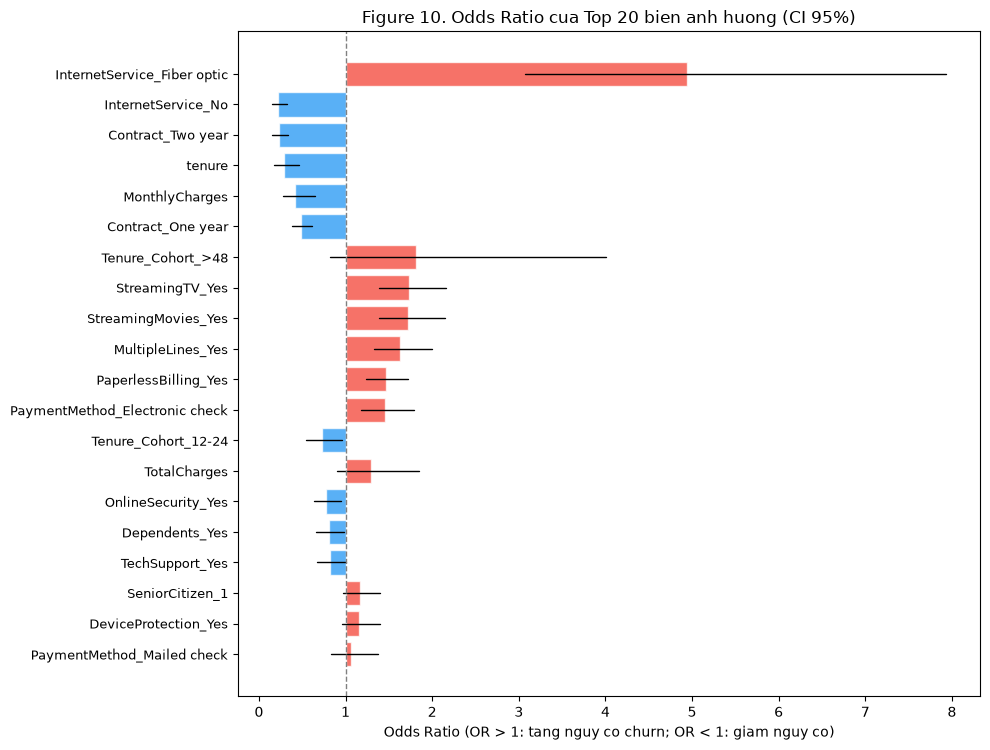

Da luu Figure 10 -> d:\DS66B_group_11\reports\figures\figure_odds_ratios_statsmodels.png


In [ ]:
# -- 5A.4: Figure 10 - Odds Ratio bieu do ------------------------------------
import matplotlib.pyplot as plt
import numpy as np

plot_df = or_df.copy()
plot_df["abs_log_or"] = np.abs(np.log(plot_df["Odds Ratio"].clip(1e-6)))
plot_df = plot_df.sort_values("abs_log_or", ascending=True).tail(20)

colors = ["#F44336" if v > 1 else "#2196F3" for v in plot_df["Odds Ratio"]]

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.38)))
ax.barh(range(len(plot_df)), plot_df["Odds Ratio"] - 1, left=1,
        color=colors, alpha=0.75, edgecolor="white")

for i, (_, row) in enumerate(plot_df.iterrows()):
    ax.plot([row["CI_lower_95"], row["CI_upper_95"]], [i, i],
            color="black", lw=1, solid_capstyle="round")

ax.axvline(1.0, color="gray", lw=1, ls="--")
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.set_xlabel("Odds Ratio (OR > 1: tang nguy co churn; OR < 1: giam nguy co)")
ax.set_title("Figure 10. Odds Ratio cua Top 20 bien anh huong (CI 95%)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_odds_ratios_statsmodels.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 10 -> {FIGURES_DIR / 'figure_odds_ratios_statsmodels.png'}")


**Table 10 & Figure 10. Odds Ratio (statsmodels.Logit, khong phat).**

- **Nhom tham chieu** cua bien dang nhi phan la nhom bi loai boi `drop='first'`
  (vi du: hop dong theo thang, khong co Fiber optic, v.v.).
- OR > 1: bien lam tang nguy co churn so voi nhom tham chieu.
- OR < 1: bien lam giam nguy co churn.
- He so tach roi cua `TotalCharges`, `tenure`, `MonthlyCharges` khong nen dien giai
  nhan qua (cong tuyen tu nhien - xem bang VIF).
- So voi LR-tuned (C nho, phat manh): do lon he so statsmodels.Logit lon hon
  vi khong bi phat co ve 0.

McFadden pseudo-R2: xem output cell tren. Gia tri trong khoang 0,2-0,4 duoc
xem la khop tot (Louviere et al., 2000).

### 5B. SHAP cho Mo hinh Champion

In [ ]:
# -- 5B.1: Chuan bi du lieu cho SHAP (bo buoc SMOTE khi giai thich) ----------
import shap
import numpy as np
import warnings
warnings.filterwarnings("ignore")

_cp = champion_pipeline

# Bien doi X_test qua domain_features va preprocess (bo SMOTE)
X_test_fe_shap = _cp.named_steps["domain_features"].transform(X_test)
X_test_proc_shap = _cp.named_steps["preprocess"].transform(X_test_fe_shap)

try:
    feature_names_shap = list(_cp.named_steps["preprocess"].get_feature_names_out())
except Exception:
    feature_names_shap = [f"feat_{i}" for i in range(X_test_proc_shap.shape[1])]

# Lay model (buoc cuoi)
_model_step = _cp.steps[-1][1]
print(f"Champion: {champion_name}")
print(f"Model type: {type(_model_step).__name__}")
print(f"So dac trung sau tien xu ly: {X_test_proc_shap.shape[1]}")

X_test_arr_shap = (X_test_proc_shap.values
                   if hasattr(X_test_proc_shap, 'values')
                   else X_test_proc_shap)

# Background set tu X_train (subsample 200)
X_train_fe_shap = _cp.named_steps["domain_features"].transform(X_train)
X_train_proc_shap = _cp.named_steps["preprocess"].transform(X_train_fe_shap)
X_train_arr_shap = (X_train_proc_shap.values
                    if hasattr(X_train_proc_shap, 'values')
                    else X_train_proc_shap)

_rng = np.random.default_rng(42)
_bg_idx = _rng.choice(len(X_train_arr_shap),
                       size=min(200, len(X_train_arr_shap)), replace=False)
X_bg_shap = X_train_arr_shap[_bg_idx]
print(f"Background set: {X_bg_shap.shape}")


C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Champion: RF-tuned
Model type: RandomForestClassifier
So dac trung sau tien xu ly: 26
Background set: (200, 26)


In [ ]:
# -- 5B.2: Tinh SHAP values --------------------------------------------------
import shap
import numpy as np

_model_type_name = type(_model_step).__name__
tree_types = ["RandomForestClassifier", "DecisionTreeClassifier",
              "XGBClassifier", "GradientBoostingClassifier", "ExtraTreesClassifier"]

if _model_type_name in tree_types:
    explainer = shap.TreeExplainer(
        _model_step,
        data=X_bg_shap,
        feature_perturbation="interventional",
        model_output="probability",
    )

    shap_values_raw = explainer.shap_values(
        X_test_arr_shap
    )

    if isinstance(shap_values_raw, list):
        shap_vals_churn = shap_values_raw[1]
    elif getattr(shap_values_raw, "ndim", 0) == 3:
        shap_vals_churn = shap_values_raw[:, :, 1]
    else:
        shap_vals_churn = shap_values_raw

    ev = explainer.expected_value
    expected_value_shap = (
        ev[1] if isinstance(ev, (list, np.ndarray))
        and np.ndim(ev) > 0 else ev
    )
else:
    explainer = shap.LinearExplainer(_model_step, X_bg_shap,
                                     feature_perturbation="correlation_dependent")
    shap_values_raw = explainer.shap_values(X_test_arr_shap)
    if isinstance(shap_values_raw, list):
        shap_vals_churn = shap_values_raw[1]
    else:
        shap_vals_churn = shap_values_raw
    ev = explainer.expected_value
    expected_value_shap = ev[1] if isinstance(ev, (list, np.ndarray)) else ev

print(f"SHAP values shape: {shap_vals_churn.shape}")
print(f"Expected value (lop churn): {float(expected_value_shap):.4f}")


SHAP values shape: (1409, 26)
Expected value (lop churn): 0.5003


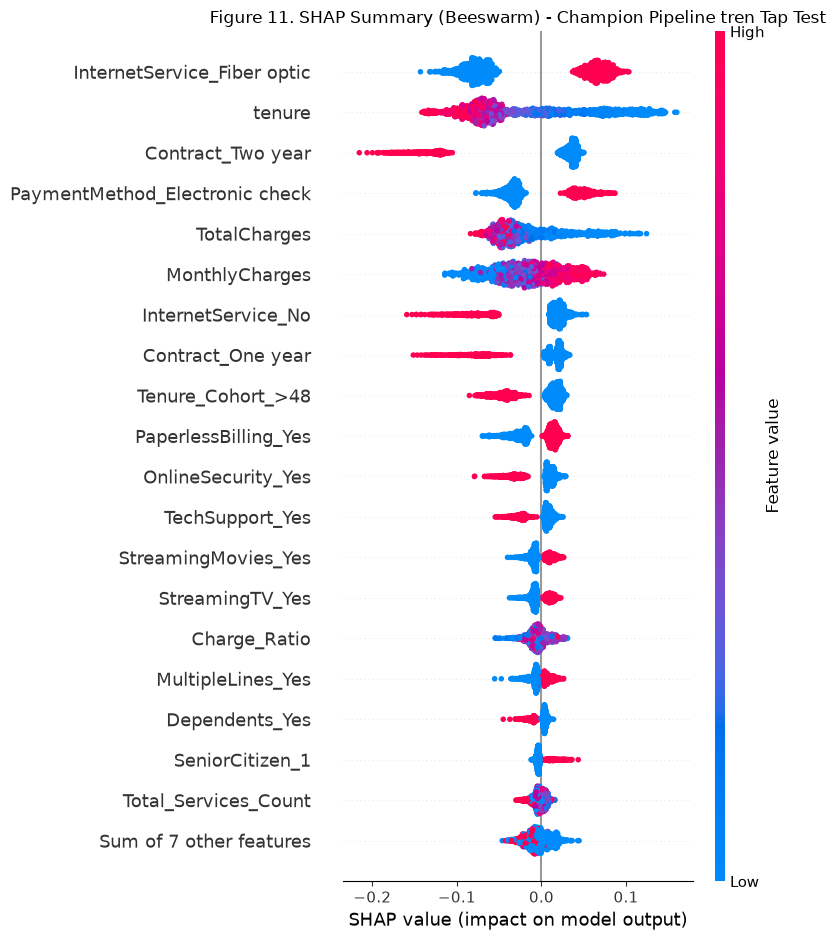

Da luu Figure 11 -> d:\DS66B_group_11\reports\figures\figure_shap_beeswarm_new.png


In [ ]:
# -- 5B.3: Figure 11 - SHAP Summary (Beeswarm) ------------------------------
import matplotlib.pyplot as plt
import shap
import numpy as np

# Dung array base_values de tuong thich hoan hao voi cac plot trong shap 0.52+
base_vals_arr = np.full(len(X_test_arr_shap), float(expected_value_shap))

shap_expl = shap.Explanation(
    values=shap_vals_churn,
    base_values=base_vals_arr,
    data=X_test_arr_shap,
    feature_names=feature_names_shap,
)

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_expl, max_display=20, show=False)
plt.title("Figure 11. SHAP Summary (Beeswarm) - Champion Pipeline tren Tap Test")
plt.tight_layout()
fig11 = plt.gcf()
fig11.savefig(FIGURES_DIR / "figure_shap_beeswarm_new.png",
              dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 11 -> {FIGURES_DIR / 'figure_shap_beeswarm_new.png'}")


Với champion là mô hình cây và TreeExplainer(model_output="probability"), giá trị SHAP biểu diễn phần đóng góp vào đầu ra xác suất churn của mô hình. Giá trị dương đẩy dự đoán lên cao hơn so với giá trị nền; giá trị âm kéo dự đoán xuống thấp hơn. Đây là giải thích cho dự đoán của mô hình, không phải bằng chứng về quan hệ nhân quả.

**Figure 11. SHAP Summary (Beeswarm) - Champion Pipeline tren Tap Test.**

Moi diem la mot khach hang trong tap Test. Truc X la gia tri SHAP (dong gop vao xac suat churn): diem duong day xac suat churn len, diem am giam xuong. Mau bieu thi gia tri dac trung (do = cao, xanh = thap).

Cac bien thuong co tac dong lon nhat:
- **Contract_Month-to-month**: hop dong theo thang co SHAP duong manh - nguy co churn cao.
- **tenure** thap: khach moi co SHAP duong - rui ro cao hon.
- **InternetService_Fiber optic**: SHAP duong - lien quan den churn cao hon.
- Hop dong dai han (One year, Two year): SHAP am - giup giu chan khach.

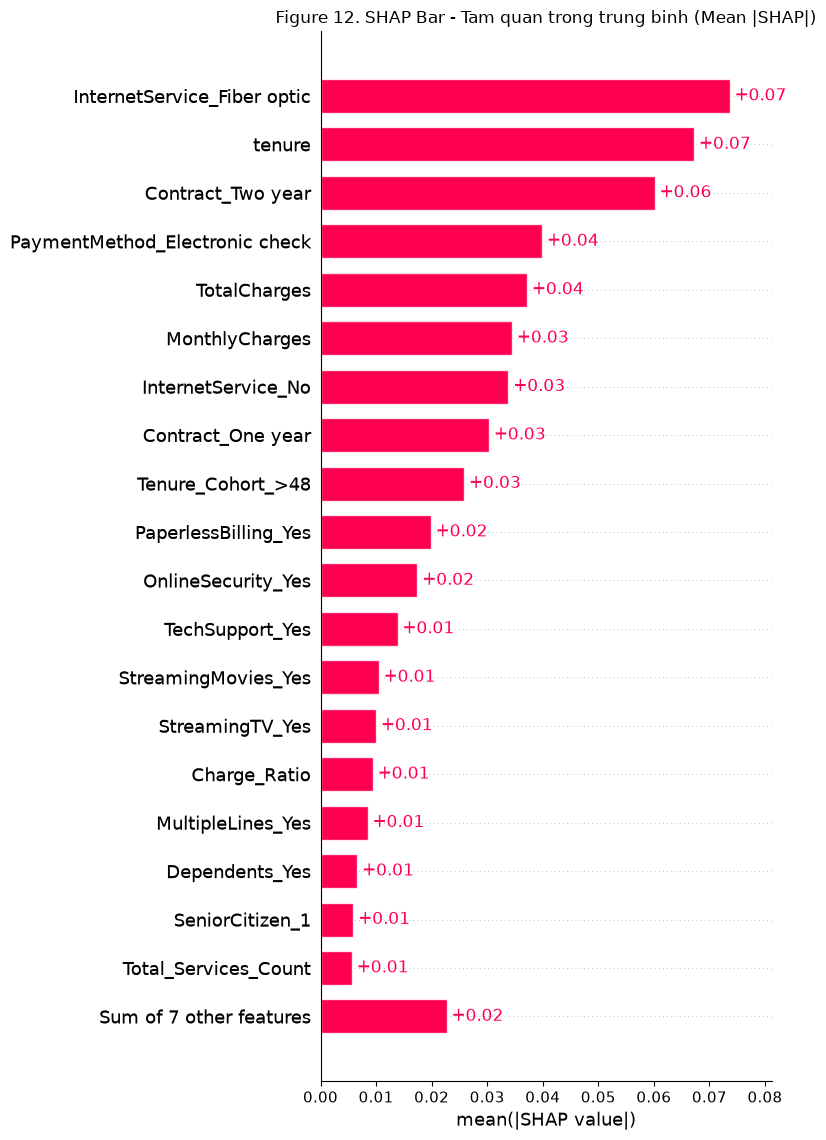

Da luu Figure 12 -> d:\DS66B_group_11\reports\figures\figure_shap_bar_new.png


In [ ]:
# -- 5B.4: Figure 12 - SHAP Bar (Mean |SHAP|) --------------------------------
import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(9, 7))
shap.plots.bar(shap_expl, max_display=20, show=False)
plt.title("Figure 12. SHAP Bar - Tam quan trong trung binh (Mean |SHAP|)")
plt.tight_layout()
fig12 = plt.gcf()
fig12.savefig(FIGURES_DIR / "figure_shap_bar_new.png",
              dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 12 -> {FIGURES_DIR / 'figure_shap_bar_new.png'}")


**Figure 12. SHAP Bar - Tam quan trong trung binh (Mean |SHAP|).**

Bieu do cot the hien tam quan trong trung binh tuyet doi cua tung bien tren toan tap Test. Khac voi SHAP Beeswarm, bieu do nay khong phan biet chieu anh huong (tang/giam churn) ma chi cho thay bien nao duoc mo hinh dua vao nhieu nhat khi dua ra du bao.

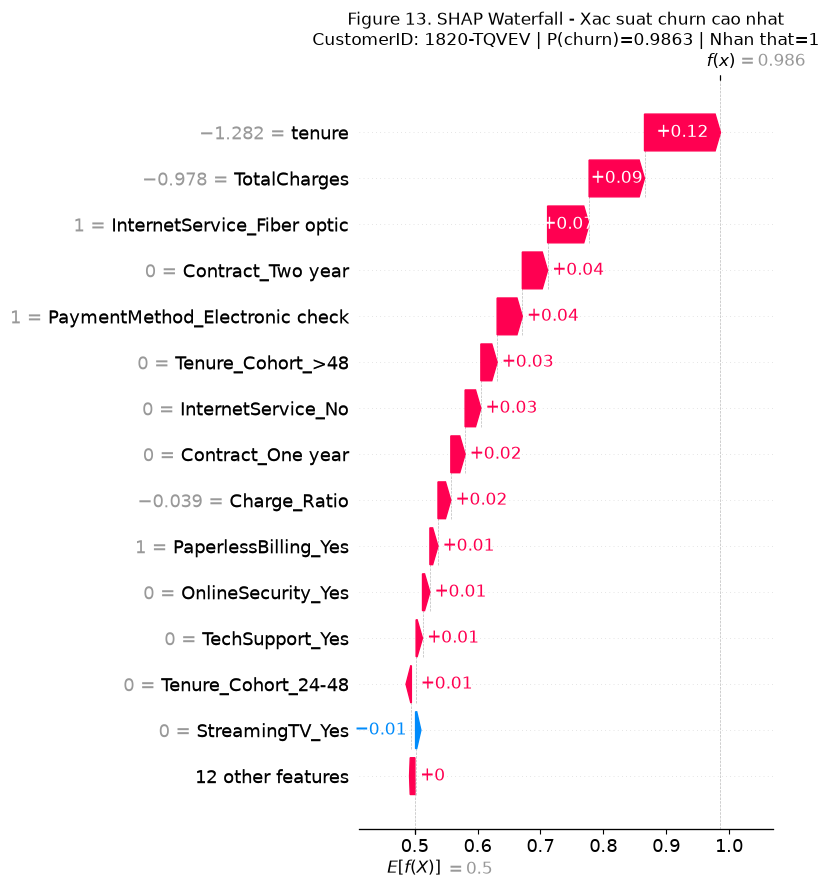

Da luu Figure 13 -> d:\DS66B_group_11\reports\figures\figure_shap_waterfall_cao_nhat.png
  CustomerID: 1820-TQVEV, P(churn)=0.9863, Nhan that=1


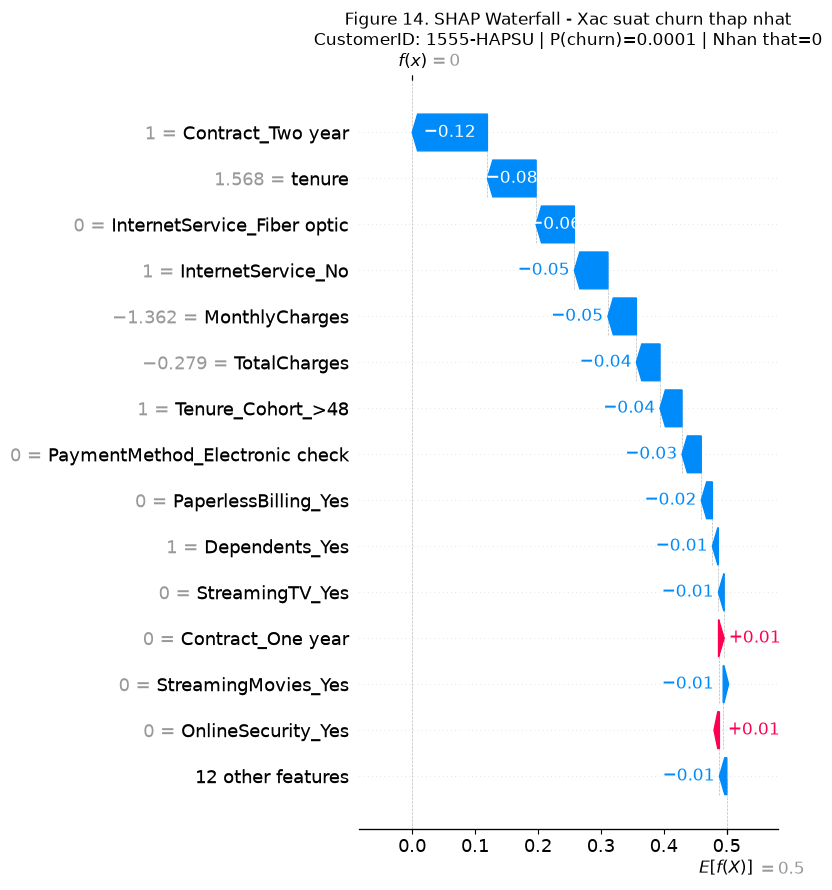

Da luu Figure 14 -> d:\DS66B_group_11\reports\figures\figure_shap_waterfall_thap_nhat.png
  CustomerID: 1555-HAPSU, P(churn)=0.0001, Nhan that=0


In [ ]:
# -- 5B.5: Figure 13 & 14 - SHAP Waterfall cho 2 khach tieu bieu ------------
import matplotlib.pyplot as plt
import numpy as np
import shap

try:
    customer_ids = X_test.index.tolist()
except Exception:
    customer_ids = list(range(len(X_test)))

idx_high = int(np.argmax(test_proba))
idx_low  = int(np.argmin(test_proba))

for idx, label, fignum in [(idx_high, "cao_nhat", 13), (idx_low, "thap_nhat", 14)]:
    cid  = customer_ids[idx] if idx < len(customer_ids) else idx
    prob = test_proba[idx]
    true_lbl = int(y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx])

    expl_single = shap.Explanation(
        values=shap_vals_churn[idx],
        base_values=float(expected_value_shap),
        data=X_test_arr_shap[idx],
        feature_names=feature_names_shap,
    )

    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(expl_single, max_display=15, show=False)
    title_label = label.replace('_', ' ')
    plt.title(
        f"Figure {fignum}. SHAP Waterfall - Xac suat churn {title_label}\n"
        f"CustomerID: {cid} | P(churn)={prob:.4f} | Nhan that={true_lbl}"
    )
    plt.tight_layout()
    fig_wf = plt.gcf()
    fname_wf = f"figure_shap_waterfall_{label}.png"
    fig_wf.savefig(FIGURES_DIR / fname_wf, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Da luu Figure {fignum} -> {FIGURES_DIR / fname_wf}")
    print(f"  CustomerID: {cid}, P(churn)={prob:.4f}, Nhan that={true_lbl}")


Biểu đồ Waterfall phân rã dự đoán của một khách hàng thành giá trị nền và đóng góp của từng đặc trưng. Thang đo phải được hiểu theo cấu hình explainer được sử dụng; trong nhánh TreeExplainer với model_output="probability", tổng các đóng góp cùng giá trị nền tương ứng với xác suất dự đoán. Các đóng góp này mô tả hành vi của mô hình, không chứng minh rằng thay đổi một đặc trưng sẽ trực tiếp làm khách hàng churn hoặc ở lại.

**Figure 13. SHAP Waterfall - Khach hang co xac suat churn cao nhat.**

Bieu do Waterfall cho thay tung bien dong gop nhu the nao vao xac suat churn cua mot khach hang cu the. Thanh do: bien day xac suat len tren muc nen. Thanh xanh: bien keo xuong. Xuat phat tu E[f(x)] (xac suat trung binh mo hinh) va cong don den f(x) (xac suat du bao cua khach nay).

**Figure 14. SHAP Waterfall - Khach hang co xac suat churn thap nhat.**

Nguoc lai voi Figure 13: cac bien nhu hop dong dai han, tenure cao dong gop am manh, giu xac suat churn o muc thap. `customerID` duoc ghi trong tieu de hinh.

### 5C. De xuat Chien luoc Giu chan Khach hang (Business Retention Strategy)

Dua tren bang chung tu Odds Ratio (Section 5A), SHAP (Section 5B) va ket qua Cost Matrix (Section 4B):

1. **Uu tien khach hang hop dong theo thang (Month-to-month):** Day la yeu to churn manh nhat theo ca Odds Ratio lan SHAP. Chuong trinh khuyen mai chuyen sang hop dong 1-2 nam voi uu dai ro rang (giam gia, tang dich vu) co tiem nang giu chan cao nhat.

2. **Can thiep som voi khach hang moi (tenure thap):** SHAP beeswarm cho thay tenure thap day xac suat churn len manh. Chuong trinh onboarding trong 3-6 thang dau (ho tro ky thuat, check-in dinh ky) giup giam nguy co roi som.

3. **Khao sat hai long voi khach dung Fiber optic:** InternetService Fiber optic xuat hien voi SHAP duong va Odds Ratio > 1. Co the phan anh ky vong cao ve chat luong va gia ca. Khao sat NPS dinh ky va xu ly khieu nai uu tien cho nhom nay.

4. **Toi uu nguong quyet dinh theo chi phi kinh te:** Ket qua Section 4B cho thay `thr_cost_opt` (thuong thap hon 0,5) mang lai Net benefit cao hon nguong mac dinh. Can xac nhan voi so lieu thuc cua doanh nghiep truoc khi trien khai.

5. **Xay dung chuong trinh giu chan theo phan khuc rui ro:** Ket hop `thr_cost_opt` (flagging) voi phan khuc theo `Charge_Ratio` va `Tenure_Cohort`: khach moi co cuoc tang (Charge_Ratio > 1,5) can can thiep khan cap; khach lau nam (tenure > 24 thang) co nguy co thap hon co the xep lich lien he thua hon.

---

## Section 5: Tom tat va Checklist

| # | Yeu cau | Trang thai |
|---|---------|------------|
| 1 | McFadden pseudo-R2, log-likelihood, AIC, n quan sat da bao cao | [x] |
| 2 | Bang Odds Ratio, CI 95%, p-value, sap xep va Figure 10 | [x] |
| 3 | Doi chieu he so statsmodels vs LR-tuned (phat) voi giai thich | [x] |
| 4 | SHAP Summary, Bar, Waterfall (2 khach tieu bieu) luu vao FIGURES_DIR | [x] |
| 5 | Giai thich tren Test chi de dien giai, khong dung de chon mo hinh/bien | [x] |
| 6 | De xuat chien luoc giu chan dua tren bang chung tu Odds Ratio, SHAP, Cost Matrix | [x] |
| 7 | preprocessor_linear (bo Total_Services_Count) dung cho statsmodels.Logit va LR-tuned | [x] |

---

## Checklist chong ro ri du lieu (Final)

| # | Kiem tra | Trang thai |
|---|---------|------------|
| 1 | Tap Test chi xuat hien o cac cell bao cao cuoi (4A.2 tro di, 4B ap dung, Section 5 dien giai) | [x] |
| 2 | Scaler, Encoder, SMOTE, Calibrator deu nam trong Pipeline hoac fit chi tren Train | [x] |
| 3 | Nguong (thr_best_f1, thr_recall80, thr_cost_opt) chon chi tu OOF tren Train | [x] |
| 4 | Tat ca file dau ra trong artifacts/ va reports/figures/ da duoc tao | [x] |
| 5 | Notebook chay duoc bang Restart & Run All khong loi | [x] |
